[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/VQC_PartitionedAdversarialRobustness_Kananian2025.ipynb)

# Adversarial gates inside partitioned quantum classifiers: Kananian & Jacobsen 2025 step by step

**Paper.** P. Kananian and H.-A. Jacobsen, *Adversarial Robustness of Partitioned Quantum Classifiers*, arXiv:2502.20403 [cs.ET] (v2, 6 March 2026), University of Toronto. DOI: [10.48550/arXiv.2502.20403](https://doi.org/10.48550/arXiv.2502.20403). Topic folder: *23 Adversarial attacks against QML*.

**What this notebook does.** It rebuilds the experimental part of the paper on a CPU, with an exact state-vector simulator written in PyTorch and *checked gate by gate against PennyLane QNodes*:

1. a hardware-efficient variational quantum classifier (amplitude encoding, layers of `Rot` gates and a cyclic CNOT ring, one or two ancilla qubits that are measured) is trained on MNIST, Fashion-MNIST (16x16 images) and a HOG-feature version of CIFAR-10 (airplane vs truck);
2. the classifier is frozen and an adversary **plants trainable "adversarial gates" in the middle of the circuit** (rotation + controlled-phase layers that start as the identity), which is what tampering with a wire cut or a teleported state amounts to;
3. misclassification rate is plotted against *attack strength* (summed normalised Hilbert-Schmidt distance of the planted unitaries from the identity) for: input-layer vs mid-circuit blocks, one block vs three blocks, global vs local (3 or 4 qubits) gates, short vs long blocks;
4. the paper's theory is tested numerically: Theorem 6.1 (deterministic bound on the confidence shift) and Theorem 6.3 (probabilistic, Chebyshev-type bound), plus the Section 4 statement that perturbing the prepared states of a wire cut is *exactly* a gate inserted into the circuit (a full wire cut of a small instance of the same classifier, reconstructed from measure-and-prepare terms);
5. a side-by-side table of every number and every qualitative claim we can check, each with a verdict.

**How to run.** Open in Google Colab, choose a **CPU** runtime, *Run all*. `FAST_MODE = True` (default in the configuration cell) is a class demo (about 10 minutes); `FAST_MODE = False` is the larger budget documented in the configuration cell. All data are downloaded from public Hugging Face mirrors (no token needed; if you hit rate limits, add your own `HF_TOKEN` under Colab *Settings > Secrets*). Nothing needs a quantum computer.

**What you get at the end.** Executed figures in the style of the paper's Figures 8-12 and 29-33, a numerical check of the two theorems and of the wire-cutting equivalence, and an honest comparison with the paper's numbers.

## The paper in one page

**Problem.** To run a circuit that is wider than the available QPUs one can *cut* it (replace an identity channel on a wire by a quasi-probabilistic sum of measure-and-prepare channels, Eq. 8-11) or *teleport* qubits between nodes. In both cases the classifier is spread over several parties. A malicious party can then perturb the states it prepares or forwards. For a unitary perturbation $\hat U$ applied identically to all prepared states, Eq. 13 shows that the reconstructed circuit is simply the original circuit with the gate $\hat U$ **inserted in an intermediate layer**. An unpartitioned classifier can only be attacked at its input; a partitioned one offers several extra attack surfaces. The paper therefore studies classifiers attacked by gates $\hat U_0,\dots,\hat U_n$ inserted between layers (Eq. 4-7).

**Classifier.** $K$-class classification with $y_k(\sigma)=\mathrm{Tr}\big(\Pi_k\,\mathcal E(\sigma\otimes|a\rangle\langle a|)\big)$, $d=\lceil\log_2 c\rceil$ data qubits (amplitude encoding of a $c$-dimensional input), $d_a=\lceil\log_2 K\rceil$ ancillas, hardware-efficient ansatz of $\ell$ layers: `Rot` on every qubit, then a cyclic CNOT ring (qubit $i$ to $i+1$, last to first). Output = probabilities of the $d_a$ ancilla qubits.

**Attack.** White box, untargeted. The classifier is frozen; the adversarial layers have the same structure with CNOT replaced by CRZ$(\varphi)$, so all-zero parameters give the identity. They are trained to *maximise* the cross-entropy with SGD (the strength penalty $\gamma$ is 0). After every epoch the paper records the test misclassification rate and the *attack strength* $\sum_i \|\hat U_i-I\|_2/\sqrt{2^{d_{adv}}}$.

**Theory.** Theorem 6.1: $|y_k-\hat y_k|\le \tfrac12\big(\|{\rm id}-\hat{\mathcal U}_0\|_\diamond+\sum_i\|{\rm id}-\hat{\mathcal U}_i\|_\diamond\big)\le\sum_i\min_{\phi}\|I-e^{i\phi}\hat U_i\|_{op}$ (and the same with the Hilbert-Schmidt norm, Corollary 6.2). Theorem 6.3: for Haar-random inputs, $|y_k-\hat y_k|<\delta$ with probability at least $1-\dfrac{4\|\Pi_k\|_2^2\sum_i\|I-\hat U_i\|_2^2}{D(D+1)\delta^2}$.

**Data and numbers the paper gives.** MNIST and Fashion-MNIST downsampled to 16x16 (binary: classes 0/1, four-class: 0-3), CIFAR-10 classes 0/9 with HOG features (576 numbers). Table 1 clean test accuracy: MNIST binary 99.67% (10 layers) / 99.86% (20), four-class 90.40% (20) / 92.18% (40); FMNIST binary 94.80% / 94.75%, four-class 79.80% / 84.18%; CIFAR-2 (80 layers) 83.05%. All adversarial results are *plots* (Figures 8-33, mean of three runs); the text states qualitative conclusions, which are the claims we can test.

### What follows the paper and what had to be chosen

The paper trains and attacks 9-11 qubit circuits with up to 80 layers on the full datasets, three runs per curve, and gives no number of attack epochs. A free Colab CPU cannot do that, so every deviation below is deliberate and marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Simulator | PennyLane + Keras, back-propagation | exact state-vector simulator in PyTorch (complex64, autograd) that applies the same gates; **asserted equal to the PennyLane QNode** (max probability difference < 1e-5) at full depth for every architecture used |
| Rot convention | $RZ(\omega_1)RY(\omega_2)RZ(\omega_3)$ | `qml.Rot(phi, theta, omega)` (same family of gates, parameters are free) |
| Train / test size | full sets (e.g. 12,665 / 2,115 for MNIST 0/1) | `N_TRAIN` / `N_TEST` stratified random subsets of the official splits (FAST and full values in the configuration cell) |
| Classifier init, loss, optimiser | init not stated; Adam, batch 64, lr 1e-3 then 1e-4 (binary), three lr phases (four-class), CIFAR lr 5e-4 | weights $\\mathcal N(0,0.3^2)$; Adam, batch 64; cross-entropy on the measured probabilities; epochs reduced and lr 2x larger (full) or 5x larger (FAST), see config |
| Four-class depth 40, CIFAR-2 depth 80 | both | four-class **depth 20 only**, CIFAR-2 depth 80 (FAST: reduced training); depth 40 is skipped because it doubles the cost |
| Adversarial optimiser | SGD, lr 1e-3 (MNIST), 5e-3 (FMNIST, CIFAR-2), batch 64 / 256, "many" epochs | SGD **with a 3x to 60x larger learning rate** (MNIST 0.03, Fashion-MNIST 0.05, four-class 0.1, CIFAR-2 0.3; MNIST 0.05 in FAST) and batch 64 everywhere, because we take about 10-30 steps per epoch instead of about 200-400 and only a handful of epochs; the curves are traced with the same measurements |
| Number of runs | 3 per curve | 1 per scenario, 2 seeds (input layer and mid-circuit block) for the binary MNIST/FMNIST comparisons in the full run |
| Local gates | qubits 3,4,5 (3-qubit) and 5-8 (4-qubit), 1-indexed | same qubits; the CRZ ring inside the block is cyclic within the block (CHOICE, the paper only says the block is "similar to" a global one) |
| Input-layer block | acts on all qubits including ancillas (Appendix C.3.1.2) | same |
| Theorem 6.3 constants | no ancilla in the theorem; experiments use it anyway | $D=2^{n}$ ($n$ = all qubits), $\|\Pi_k\|_2^2=2^{d}$, $\|I-\hat U_i\|_2^2=2^{n}s_i^2$ with $s_i$ the normalised distance (CHOICE, the paper does not spell the constants out) |
| Wire-cutting simulation | not simulated in the paper (Appendix C.1: too costly) | a **full wire cut of a 5-qubit instance of the same architecture** (4^5 = 1024 Pauli terms, Eq. 9) shows the Section 4 equivalence exactly |
| Missing | Figures 21-28 (CIFAR local gates, gamma sweeps), CIFAR bound for 3 blocks | not reproduced (budget) |

## 1. Setup: installs, configuration, imports

In [1]:
# Installs. Colab already ships numpy, pandas, scikit-learn, matplotlib, torch, pyarrow and Pillow.
# The guard keeps a local environment (that already has everything) untouched.
import sys, importlib.util
IN_COLAB = "google.colab" in sys.modules
_needed = ["pennylane", "torch", "pyarrow", "huggingface_hub", "sklearn", "PIL"]
if IN_COLAB or any(importlib.util.find_spec(m) is None for m in _needed):
    !pip -q install "pennylane==0.45.1" huggingface_hub pyarrow pillow
    # A runtime restart is normally NOT required; if an import below fails, restart the runtime once and run again.

In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
SEED = 42
FAST_MODE = False          # True: class demo (about 10 min). False: the larger budget below (about 1-1.5 h on a loaded laptop CPU).
DATA_DIR = "qc139_data"   # cache folder for the downloaded parquet files
IBM_TOKEN = ""            # unused: the paper and this notebook are noiseless simulations (kept for template uniformity)
THREADS = 1               # CHOICE: the tensors are tiny (64 x 512 amplitudes); more threads only add scheduling overhead
SIDE = 16                 # MNIST / Fashion-MNIST are downsampled to SIDE x SIDE = 256 amplitudes = 8 data qubits (paper)

# --- tasks: classes, qubits (d data qubits for the amplitude encoding + d_a ancillas), clean-model depth ---
TASKS = {  # d = ceil(log2 c), d_a = ceil(log2 K), n = d + d_a
    "bin":    dict(classes=(0, 1),       K=2, d=8,  da=1),   # MNIST / FMNIST digits 0,1 / T-shirt, trouser  (9 qubits)
    "4c":     dict(classes=(0, 1, 2, 3), K=4, d=8,  da=2),   # four-class                                      (10 qubits)
    "cifar2": dict(classes=(0, 9),       K=2, d=10, da=1),   # CIFAR-10 airplane vs truck, 576 HOG features    (11 qubits)
}

if FAST_MODE:
    CLASSIFIERS = [("MNIST", "bin", 10), ("FMNIST", "bin", 10), ("MNIST", "4c", 20), ("CIFAR10", "cifar2", 80)]
    N_TRAIN = {"bin": 800,  "4c": 500, "cifar2": 128}
    N_TEST  = {"bin": 400,  "4c": 300, "cifar2": 200}
    EPOCHS  = {"bin": [(4, 5e-3), (2, 1e-3)], "4c": [(5, 5e-3), (2, 1e-3)], "cifar2": [(2, 5e-3)]}   # (epochs, Adam lr) phases; CHOICE: larger lr than the paper (very few steps)
    ADV_EPOCHS = {"bin": 4, "4c": 2, "cifar2": 2}
    SEEDS_KEY = [SEED]                     # attack seeds for the key comparisons
    SCEN_MAIN = ["g:input", "g:q2", "g:3x(3,3,4)", "l3:q2"]                       # binary 10-layer classifiers
    SCEN_MIN  = ["g:input", "g:q2"]                                                # four-class and CIFAR-2 (FAST: CIFAR-2 only g:q2, see plan_jobs)
    CIFAR_LONG_BLOCK = False
else:
    CLASSIFIERS = [("MNIST", "bin", 10), ("MNIST", "bin", 20), ("FMNIST", "bin", 10), ("FMNIST", "bin", 20),
                   ("MNIST", "4c", 20), ("FMNIST", "4c", 20), ("CIFAR10", "cifar2", 80)]
    N_TRAIN = {"bin": 2000, "4c": 1500, "cifar2": 640}
    N_TEST  = {"bin": 1000, "4c": 800,  "cifar2": 400}
    EPOCHS  = {"bin": [(5, 2e-3), (5, 2e-4)], "4c": [(8, 2e-3), (6, 2e-4), (4, 2e-5)], "cifar2": [(8, 1e-3)]}   # paper: lr 1e-3/1e-4 for 5+5 epochs (bin), 1e-3/1e-4/1e-5 for 10+10+10 (4c), 5e-4 for 40 (CIFAR); CHOICE: lr x2 because we take far fewer steps
    ADV_EPOCHS = {"bin": 6, "4c": 4, "cifar2": 4}
    SEEDS_KEY = [SEED, SEED + 1]
    SCEN_MAIN = ["g:input", "g:q1", "g:q2", "g:q3", "g:3x(3,3,4)", "g:3x10", "l3:input", "l3:q2", "l3:3x10", "l4:q2"]
    SCEN_MIN  = ["g:input", "g:q2"]
    CIFAR_LONG_BLOCK = False   # the 40-layer block on 11 qubits costs about 10 min; set True to add it (paper Fig. 12b)
# CHOICE: attack learning rates are 3x to 60x the paper's (1e-3 MNIST, 5e-3 FMNIST and CIFAR-2) because we take far fewer SGD steps
ADV_LR = {"MNIST": 5e-2 if FAST_MODE else 3e-2, "FMNIST": 5e-2, "4c": 1e-1, "cifar2": 3e-1}    # by dataset for the binary task, by task for four-class and CIFAR-2 (deeper/wider circuits have smaller gradients)
ADV_BATCH = 64            # CHOICE: paper uses 64 (binary) and 256 (four-class); 64 gives more steps per epoch on our small subsets
INIT_STD = 0.3            # CHOICE: classifier weights ~ N(0, INIT_STD^2) (paper: not stated)
CLF_BATCH = 64            # paper
CONFS = (0.90, 0.95, 0.99)  # confidence levels of Theorem 6.3 (paper Figs. 29-33)
print(f"FAST_MODE={FAST_MODE}  classifiers={CLASSIFIERS}")

FAST_MODE=False  classifiers=[('MNIST', 'bin', 10), ('MNIST', 'bin', 20), ('FMNIST', 'bin', 10), ('FMNIST', 'bin', 20), ('MNIST', '4c', 20), ('FMNIST', '4c', 20), ('CIFAR10', 'cifar2', 80)]


In [3]:
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"   # no tqdm bars in the saved outputs
import io, time, json, math, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn.functional as F
import pennylane as qml
import sklearn
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from PIL import Image
from huggingface_hub import hf_hub_download
warnings.filterwarnings("ignore")

# Hugging Face token: not needed here (all three datasets are public); resolved only from the environment / Colab secrets
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

# seeds everywhere
np.random.seed(SEED); torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(THREADS)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.25, "savefig.dpi": 80})
print("torch", torch.__version__, "| pennylane", qml.__version__, "| numpy", np.__version__, "| sklearn", sklearn.__version__,
      "| pandas", pd.__version__)
T_NOTEBOOK_START = time.time()

torch 2.14.1+cpu | pennylane 0.45.1 | numpy 2.5.4 | sklearn 1.9.1 | pandas 3.0.6


## 2. The simulator: layers of `Rot`, a CNOT ring and CRZ rings, written for speed

PennyLane's `default.qubit` with back-propagation is what the paper uses. A 9-qubit, 20-layer circuit has about 400 gates, and training it for thousands of steps through Python-level gate objects is slow on a CPU. We therefore keep the *same gates* but apply them to a batch of state vectors with a few large tensor operations:

* the `Rot` gates of one layer act on different qubits, so their tensor product is applied in groups of at most four qubits (a $2^g\times 2^g$ Kronecker product, then one `einsum`);
* the **cyclic CNOT ring is a fixed permutation of the $2^n$ basis states** (CNOT is a classical reversible gate), so a whole ring is one index lookup `state[:, perm]`;
* the **CRZ ring is diagonal**: CRZ$(\varphi)$ multiplies $|c,t\rangle$ by $e^{-i\varphi\,c\,(1-2t)/2}$, so a whole ring is one element-wise multiplication by $\exp(-\tfrac{i}{2}A\varphi)$ with $A_{x,j}=c_j(x)(1-2t_j(x))$;
* amplitude encoding puts the L2-normalised input on the top $d$ qubits, the ancillas stay in $|0\rangle$; the class probabilities are the marginal of the **bottom $d_a$ qubits** (Fig. 7 of the paper).

The next cell is the whole simulator; the cell after it proves, with PennyLane, that it implements the same circuit.

In [4]:
import math, numpy as np, torch

CDT = torch.complex64

def bit_table(n):
    """bits[x, q] = value of qubit q (q = 0 is the most significant bit = topmost wire) in basis state x."""
    x = np.arange(2 ** n)[:, None]
    return (x >> (n - 1 - np.arange(n))[None, :]) & 1

def cnot_ring_perm(n):
    """Composite permutation of the cyclic CNOT ring: CNOT(0,1), CNOT(1,2), ..., CNOT(n-2,n-1), CNOT(n-1,0) applied in this order.
    Returns idx such that new_state = state[:, idx]."""
    b = bit_table(n).copy()
    for c in list(range(n - 1)) + [n - 1]:
        t = (c + 1) % n
        b[:, t] ^= b[:, c]
    y = (b * (1 << (n - 1 - np.arange(n)))[None, :]).sum(1)      # image of every basis state
    inv = np.empty_like(y); inv[y] = np.arange(2 ** n)
    return torch.as_tensor(inv, dtype=torch.long)

def crz_sign_matrix(k):
    """A[x, i] = control_i(x) * (1 - 2 * target_i(x)) for the cyclic ring of CRZ gates on k qubits (control i, target (i+1) mod k)."""
    b = bit_table(k)
    cols = [b[:, i] * (1 - 2 * b[:, (i + 1) % k]) for i in range(k)]
    return torch.as_tensor(np.stack(cols, 1), dtype=torch.float32)

def rot_mats(p):
    """p: (..., 3) angles (phi, theta, omega) of qml.Rot -> (..., 2, 2) complex matrices  RZ(omega) RY(theta) RZ(phi)."""
    phi, th, om = p[..., 0], p[..., 1], p[..., 2]
    c, s = torch.cos(th / 2), torch.sin(th / 2)
    ep = torch.exp(-0.5j * (phi + om)); em = torch.exp(0.5j * (phi - om))
    m00 = ep * c; m01 = -em * s; m10 = torch.conj(em) * s; m11 = torch.conj(ep) * c
    return torch.stack([torch.stack([m00, m01], -1), torch.stack([m10, m11], -1)], -2).to(CDT)

def group_sizes(k, gmax=4):
    g = math.ceil(k / gmax); base, extra = divmod(k, g)
    return [base + 1] * extra + [base] * (g - extra)

def kron_group(ms):
    """ms: (..., g, 2, 2) -> Kronecker product over the g qubits (first qubit = most significant): (..., 2^g, 2^g)."""
    out = ms[..., 0, :, :]
    for j in range(1, ms.shape[-3]):
        m = ms[..., j, :, :]
        a, b = out.shape[-1], m.shape[-1]
        out = (out[..., :, None, :, None] * m[..., None, :, None, :]).reshape(*out.shape[:-2], a * b, a * b)
    return out

class Layout:
    """Everything that depends only on the qubit count n (and on which qubits a block acts on)."""
    def __init__(self, n, qubits=None):
        self.n = n
        self.qubits = list(range(n)) if qubits is None else list(qubits)      # qubits the rotation unit and CRZ ring act on
        self.k = len(self.qubits)
        self.groups = group_sizes(self.k)
        self.perm = cnot_ring_perm(n)
        self.A = None
        if self.k == n:
            self.A = crz_sign_matrix(n)
        else:                                                                 # CRZ ring on a sub-register: diagonal phase over the n-qubit basis
            bits = bit_table(n)[:, self.qubits]
            cols = [bits[:, i] * (1 - 2 * bits[:, (i + 1) % self.k]) for i in range(self.k)]
            self.A = torch.as_tensor(np.stack(cols, 1), dtype=torch.float32)

def apply_rot_unit(state, mats, lay):
    """state: (B, 2^n). mats: (k, 2, 2) single-qubit unitaries for lay.qubits (contiguous or not: handled qubit group by group)."""
    n = lay.n; B = state.shape[0]
    qs = lay.qubits; pos = 0
    for g in lay.groups:
        gq = qs[pos:pos + g]; pos += g
        K = kron_group(mats[pos - g:pos])                                      # (2^g, 2^g)
        if gq == list(range(gq[0], gq[0] + g)):                                # contiguous qubits: single reshape
            left, right = 2 ** gq[0], 2 ** (n - gq[0] - g)
            s = state.reshape(B, left, 2 ** g, right)
            state = torch.einsum('ij,bljr->blir', K, s).reshape(B, -1)
        else:
            raise NotImplementedError
    return state

def classifier_layers(state, w, lay):
    """w: (L, n, 3) trainable angles. One layer = Rot on every qubit, then the cyclic CNOT ring."""
    mats = rot_mats(w)                                                          # (L, n, 2, 2)
    for l in range(w.shape[0]):
        state = apply_rot_unit(state, mats[l], lay)[:, lay.perm]
    return state

def adversarial_layers(state, a, lay):
    """a: (L, k, 4) = 3 Rot angles + 1 CRZ angle per qubit. One layer = Rot on the k qubits, then the cyclic CRZ ring."""
    mats = rot_mats(a[..., :3])
    ph = torch.exp(-0.5j * (a[..., 3].to(torch.float32) @ lay.A.T)).to(CDT)    # (L, 2^n) diagonal of the CRZ ring
    for l in range(a.shape[0]):
        state = apply_rot_unit(state, mats[l], lay) * ph[l]
    return state

def encode(x, n, d):
    """Amplitude encoding of (B, c) data on the top d qubits, ancillas |0..0>: returns (B, 2^n) complex."""
    B, c = x.shape
    v = torch.zeros(B, 2 ** d, dtype=torch.float32); v[:, :c] = x
    v = v / v.norm(dim=1, keepdim=True).clamp_min(1e-12)
    out = torch.zeros(B, 2 ** d, 2 ** (n - d), dtype=CDT); out[:, :, 0] = v.to(CDT)
    return out.reshape(B, -1)

def run(x_enc, w, lay, blocks=()):
    """x_enc: encoded state (B, 2^n). w: (L, n, 3) classifier angles. blocks: list of (q, a, block_layout) meaning an adversarial block
    with parameters a (L_adv, k, 4) acting on the qubits of block_layout sits after classifier layer q (q = 0: on the input state,
    q = L: just before the measurement). Returns the final state."""
    L = w.shape[0]; state = x_enc; prev = 0
    mats = rot_mats(w)
    for q in sorted({b[0] for b in blocks} | {L}):
        for l in range(prev, q):
            state = apply_rot_unit(state, mats[l], lay)[:, lay.perm]
        prev = q
        for (pos, a, blay) in blocks:
            if pos == q:
                state = adversarial_layers(state, a, blay)
    return state

def class_probs(state, n, d, K):
    """Outcome probabilities of measuring the bottom da qubits (ancillas): (B, 2^da); labels beyond K are folded away (K = 2^da here)."""
    p = (state.real ** 2 + state.imag ** 2).reshape(state.shape[0], 2 ** d, 2 ** (n - d)).sum(1)
    return p[:, :K]

### Proof that the simulator equals the PennyLane circuit

`make_qnode` builds the circuit of Fig. 7 as a real PennyLane `QNode` (amplitude embedding, `qml.Rot`, `qml.CNOT`, `qml.CRZ`, `qml.probs` on the ancilla wires). The cell compares its output probabilities with the simulator for every architecture used in the notebook, at the **full depth** (10, 20 and 80 layers) with random weights and adversarial blocks (global and local, at several positions).

In [5]:
def make_qnode(n, d, L, w, blocks):
    # The PennyLane circuit of Fig. 7. w: numpy (L, n, 3). blocks: list of (position q, qubit list, params numpy (L_adv, k, 4)).
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev)
    def circ(x):
        qml.AmplitudeEmbedding(x, wires=range(d), pad_with=0.0, normalize=True)      # top d qubits; ancillas stay |0>
        cur = 0
        for q in sorted({b[0] for b in blocks} | {L}):
            for l in range(cur, q):                                                  # classifier layers
                for i in range(n):
                    qml.Rot(*w[l][i], wires=i)
                for i in range(n):
                    qml.CNOT(wires=[i, (i + 1) % n])                                 # cyclic ring
            cur = q
            for (pos, qubits, a) in blocks:                                           # adversarial block(s) after layer q
                if pos == q:
                    for l in range(a.shape[0]):
                        for j, qb in enumerate(qubits):
                            qml.Rot(*a[l][j][:3], wires=qb)
                        for j in range(len(qubits)):
                            qml.CRZ(a[l][j][3], wires=[qubits[j], qubits[(j + 1) % len(qubits)]])
        return qml.probs(wires=range(d, n))                                           # measure the bottom d_a (ancilla) qubits
    return circ

_layouts = {}
def get_layout(n, qubits=None):
    key = (n, None if qubits is None else tuple(qubits))
    if key not in _layouts:
        _layouts[key] = Layout(n, qubits)
    return _layouts[key]

def check_equivalence(n, d, K, L, blocks_spec, n_samples=2, seed=0):
    # blocks_spec: list of (position, qubits (None = all), L_adv). Random weights and random (not small) adversarial parameters.
    g = torch.Generator().manual_seed(seed)
    w = torch.randn(L, n, 3, generator=g)
    blocks_t, blocks_q = [], []
    for (pos, qubits, La) in blocks_spec:
        qs = list(range(n)) if qubits is None else list(qubits)
        a = 0.8 * torch.randn(La, len(qs), 4, generator=g)
        blocks_t.append((pos, a, get_layout(n, qubits))); blocks_q.append((pos, qs, a.numpy().astype(float)))
    x = torch.rand(n_samples, 2 ** d - 5, generator=g)
    p_sim = class_probs(run(encode(x, n, d), w, get_layout(n), blocks_t), n, d, K).numpy()
    circ = make_qnode(n, d, L, w.numpy().astype(float), blocks_q)
    p_qml = np.stack([circ(xi.numpy().astype(float)) for xi in x])
    return float(np.abs(p_sim - p_qml).max())

EQUIV = []
for (n, d, K, L, spec, label) in [
        (9, 8, 2, 10, [(5, None, 10)],                                   "binary, L=10, global block (10 layers) after layer 5"),
        (9, 8, 2, 20, [(0, None, 10), (10, [2, 3, 4], 10)],              "binary, L=20, input block + local 3-qubit block (qubits 3,4,5)"),
        (9, 8, 2, 10, [(3, None, 3), (5, None, 3), (8, [4, 5, 6, 7], 4)], "binary, L=10, three blocks (3 global + local 4-qubit)"),
        (10, 8, 4, 20, [(10, None, 10)],                                 "four-class, L=20, global block after layer 10"),
        (11, 10, 2, 80, [(40, None, 10)],                                "CIFAR-2, L=80, global block after layer 40")]:
    err = check_equivalence(n, d, K, L, spec)
    EQUIV.append((label, err)); print(f"{label:<68s} max |p_sim - p_PennyLane| = {err:.2e}")
assert max(e for _, e in EQUIV) < 1e-5, "the simulator does not reproduce the PennyLane circuit"
print("OK: the PyTorch simulator reproduces the PennyLane QNode for every architecture used below.")

binary, L=10, global block (10 layers) after layer 5                 max |p_sim - p_PennyLane| = 3.67e-07


binary, L=20, input block + local 3-qubit block (qubits 3,4,5)       max |p_sim - p_PennyLane| = 6.67e-07


binary, L=10, three blocks (3 global + local 4-qubit)                max |p_sim - p_PennyLane| = 1.26e-07


four-class, L=20, global block after layer 10                        max |p_sim - p_PennyLane| = 3.93e-08


CIFAR-2, L=80, global block after layer 40                           max |p_sim - p_PennyLane| = 5.81e-07
OK: the PyTorch simulator reproduces the PennyLane QNode for every architecture used below.


## 3. Data: download, downsample, HOG

* **MNIST and Fashion-MNIST** (Hugging Face `ylecun/mnist`, `zalando-datasets/fashion_mnist`): images are bilinearly downsampled from 28x28 to 16x16, giving 256 pixel values = the amplitudes of 8 qubits. Binary task: classes 0 and 1 (digit 0/1; T-shirt/top and trouser); four-class task: classes 0-3 (adds digit 2/3; pullover and dress).
* **CIFAR-10** (`uoft-cs/cifar10`), classes 0 and 9 (airplane, truck) called *CIFAR-2*: grey-scale, resized 32x32 -> 64x64, then HOG with 8x8-pixel cells and 1x1 blocks (9 orientations), 576 features = 10 data qubits after zero-padding to 1024 amplitudes. HOG is re-implemented in NumPy following `skimage.feature.hog` (central-difference gradients, unsigned orientations, `L2-Hys` block normalisation) so the notebook needs no extra package.
* Official train/test splits are kept. A **stratified random subset** of the training split (`N_TRAIN`) and of the test split (`N_TEST`) is drawn with `random_state=SEED`. All fitted quantities (classifier weights, the PCA used for plotting) use the training subset only.

In [6]:
import os, io, numpy as np, pandas as pd, torch, torch.nn.functional as F
from PIL import Image
from huggingface_hub import hf_hub_download

HF_SPECS = {
    "MNIST":  ("ylecun/mnist", "mnist/{split}-00000-of-00001.parquet", "image", "label"),
    "FMNIST": ("zalando-datasets/fashion_mnist", "fashion_mnist/{split}-00000-of-00001.parquet", "image", "label"),
    "CIFAR10": ("uoft-cs/cifar10", "plain_text/{split}-00000-of-00001.parquet", "img", "label"),
}
_cache = {}

def load_parquet(key, split, data_dir, token=None):
    if (key, split) not in _cache:
        repo, pat, icol, lcol = HF_SPECS[key]
        path = hf_hub_download(repo, pat.format(split=split), repo_type="dataset", token=token or None, local_dir=data_dir)
        _cache[(key, split)] = pd.read_parquet(path, columns=[icol, lcol]).rename(columns={icol: "image", lcol: "label"})
    return _cache[(key, split)]

def decode(cell, mode="L"):
    return Image.open(io.BytesIO(cell["bytes"])).convert(mode)

def select_rows(df, classes, n, seed):
    """Rows whose label is in `classes`; if n is smaller than their number, a stratified random subset of n rows (random_state=seed)."""
    from sklearn.model_selection import train_test_split
    sub = df[df["label"].isin(classes)].reset_index(drop=True)
    if n is not None and n < len(sub):
        keep, _ = train_test_split(np.arange(len(sub)), train_size=n, stratify=sub["label"].to_numpy(), random_state=seed)
        sub = sub.iloc[np.sort(keep)].reset_index(drop=True)
    return sub

def pixel_features(sub, side=16):
    """Decoded 28x28 grey images -> (N, side*side) float32 in [0, 1] (bilinear, antialiased downsampling) and labels."""
    arr = np.stack([np.asarray(decode(c), dtype=np.float32) / 255.0 for c in sub["image"]])
    t = F.interpolate(torch.from_numpy(arr)[:, None], size=(side, side), mode="bilinear", antialias=True, align_corners=False)
    return t.reshape(len(sub), -1).numpy(), sub["label"].to_numpy()
def hog_features(gray64, cell=8, nbins=9, eps=1e-5):
    """HOG as in skimage.feature.hog(pixels_per_cell=(8, 8), cells_per_block=(1, 1), orientations=9, block_norm='L2-Hys'), re-implemented in numpy.
    gray64: (64, 64) float. Returns cell_rows * cell_cols * nbins = 576 numbers."""
    g = gray64.astype(np.float64)
    gx = np.zeros_like(g); gy = np.zeros_like(g)
    gx[:, 1:-1] = g[:, 2:] - g[:, :-2]; gy[1:-1, :] = g[2:, :] - g[:-2, :]
    mag = np.hypot(gx, gy); ang = np.rad2deg(np.arctan2(gy, gx)) % 180.0
    nr = g.shape[0] // cell; nc = g.shape[1] // cell
    out = np.zeros((nr, nc, nbins))
    b = np.minimum((ang / (180.0 / nbins)).astype(int), nbins - 1)
    for i in range(nr):
        for j in range(nc):
            m = mag[i * cell:(i + 1) * cell, j * cell:(j + 1) * cell].ravel(); bb = b[i * cell:(i + 1) * cell, j * cell:(j + 1) * cell].ravel()
            out[i, j] = np.bincount(bb, weights=m, minlength=nbins) / (cell * cell)
    v = out.reshape(nr * nc, nbins)
    v = v / np.sqrt((v ** 2).sum(1, keepdims=True) + eps ** 2)       # L2-Hys per 1x1 block: normalise, clip at 0.2, normalise again
    v = np.minimum(v, 0.2)
    v = v / np.sqrt((v ** 2).sum(1, keepdims=True) + eps ** 2)
    return v.reshape(-1)

def hog_dataset_features(sub):
    """CIFAR-10 rows -> grey, resized 32x32 -> 64x64 (bilinear), HOG with 8x8 cells -> 576 features per image."""
    feats = []
    for c in sub["image"]:
        im = decode(c, "L").resize((64, 64), Image.BILINEAR)
        feats.append(hog_features(np.asarray(im, dtype=np.float64) / 255.0))
    return np.stack(feats).astype(np.float32), sub["label"].to_numpy()

In [7]:
DS_INFO = {  # repo, class names for the classes used, short description
    "MNIST":   dict(names={0: "digit 0", 1: "digit 1", 2: "digit 2", 3: "digit 3"}, full="MNIST (ylecun/mnist)"),
    "FMNIST":  dict(names={0: "T-shirt/top", 1: "trouser", 2: "pullover", 3: "dress"}, full="Fashion-MNIST (zalando-datasets/fashion_mnist)"),
    "CIFAR10": dict(names={0: "airplane", 9: "truck"}, full="CIFAR-10 (uoft-cs/cifar10)"),
}
DATA = {}    # (dataset key, task) -> dict with numpy features/labels and the amplitude-encoded states
t0 = time.time()
needed = sorted({(ds, task) for ds, task, _ in CLASSIFIERS} | {("MNIST", "4c"), ("FMNIST", "4c"), ("CIFAR10", "cifar2"), ("MNIST", "bin"), ("FMNIST", "bin")})
for (ds, task) in needed:
    spec = TASKS[task]; n = spec["d"] + spec["da"]
    dtr = load_parquet(ds, "train", DATA_DIR, HF_TOKEN); dte = load_parquet(ds, "test", DATA_DIR, HF_TOKEN)
    s_tr = select_rows(dtr, spec["classes"], N_TRAIN[task], SEED); s_te = select_rows(dte, spec["classes"], N_TEST[task], SEED)
    feat = hog_dataset_features if ds == "CIFAR10" else pixel_features
    Xtr, ytr = feat(s_tr); Xte, yte = feat(s_te)
    remap = {c: i for i, c in enumerate(spec["classes"])}            # CIFAR 0/9 -> 0/1 ; other tasks are the identity
    ytr_m = np.array([remap[v] for v in ytr]); yte_m = np.array([remap[v] for v in yte])
    DATA[(ds, task)] = dict(Xtr=Xtr, ytr=ytr_m, Xte=Xte, yte=yte_m, ytr_orig=ytr, yte_orig=yte, n=n, d=spec["d"], K=spec["K"],
                            Etr=encode(torch.from_numpy(Xtr), n, spec["d"]), Ete=encode(torch.from_numpy(Xte), n, spec["d"]),
                            Ytr=torch.from_numpy(ytr_m).long(), Yte=torch.from_numpy(yte_m).long())
    print(f"{ds:8s} {task:7s} train {Xtr.shape} test {Xte.shape} labels {dict(zip(*[v.tolist() for v in np.unique(ytr_m, return_counts=True)]))}")
print(f"data ready in {time.time() - t0:.0f} s")

CIFAR10  cifar2  train (640, 576) test (400, 576) labels {0: 320, 1: 320}


FMNIST   4c      train (1500, 256) test (800, 256) labels {0: 375, 1: 375, 2: 375, 3: 375}


FMNIST   bin     train (2000, 256) test (1000, 256) labels {0: 1000, 1: 1000}


MNIST    4c      train (1500, 256) test (800, 256) labels {0: 359, 1: 409, 2: 361, 3: 371}


MNIST    bin     train (2000, 256) test (1000, 256) labels {0: 935, 1: 1065}
data ready in 21 s


## Dataset Exploration and Visualisation

Everything below uses the **real downloaded observations** and their **ground-truth labels**; nothing is simulated or relabelled (CIFAR-10 labels 0 and 9 are only renamed to 0 and 1 for the classifier).

### D1. Shapes, feature names, original label values and class counts

MNIST: official train 60000 rows, test 10000 rows; image size (28, 28) (L); original label values [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
   train counts per original label: {0: 5923, 1: 6742, 2: 5958, 3: 6131, 4: 5842, 5: 5421, 6: 5918, 7: 6265, 8: 5851, 9: 5949}
   test  counts per original label: {0: 980, 1: 1135, 2: 1032, 3: 1010, 4: 982, 5: 892, 6: 958, 7: 1028, 8: 974, 9: 1009}
FMNIST: official train 60000 rows, test 10000 rows; image size (28, 28) (L); original label values [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
   train counts per original label: {0: 6000, 1: 6000, 2: 6000, 3: 6000, 4: 6000, 5: 6000, 6: 6000, 7: 6000, 8: 6000, 9: 6000}
   test  counts per original label: {0: 1000, 1: 1000, 2: 1000, 3: 1000, 4: 1000, 5: 1000, 6: 1000, 7: 1000, 8: 1000, 9: 1000}


CIFAR10: official train 50000 rows, test 10000 rows; image size (32, 32) (RGB); original label values [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
   train counts per original label: {0: 5000, 1: 5000, 2: 5000, 3: 5000, 4: 5000, 5: 5000, 6: 5000, 7: 5000, 8: 5000, 9: 5000}
   test  counts per original label: {0: 1000, 1: 1000, 2: 1000, 3: 1000, 4: 1000, 5: 1000, 6: 1000, 7: 1000, 8: 1000, 9: 1000}


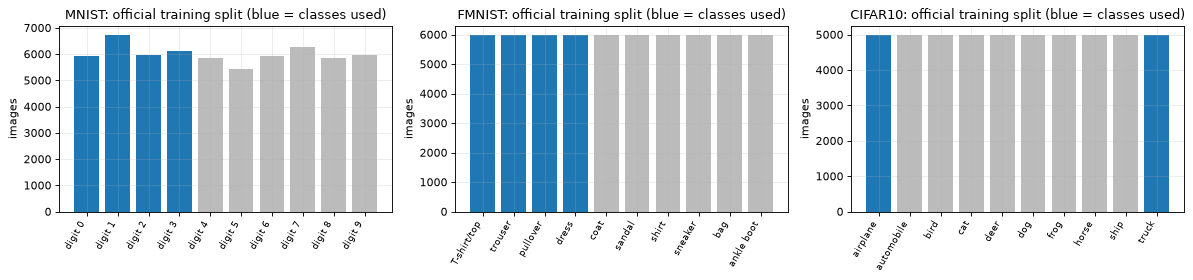

,dataset,task,qubits,train_shape,test_shape,features,train_counts,test_counts
0,CIFAR10,cifar2,11 (10 data + 1 ancilla),"(640, 576)","(400, 576)",HOG 8x8 cells x 9 orientations,"{0: 320, 9: 320}","{0: 200, 9: 200}"
1,FMNIST,4c,10 (8 data + 2 ancilla),"(1500, 256)","(800, 256)",pixels of the 16x16 downsampled image,"{0: 375, 1: 375, 2: 375, 3: 375}","{0: 200, 1: 200, 2: 200, 3: 200}"
2,FMNIST,bin,9 (8 data + 1 ancilla),"(2000, 256)","(1000, 256)",pixels of the 16x16 downsampled image,"{0: 1000, 1: 1000}","{0: 500, 1: 500}"
3,MNIST,4c,10 (8 data + 2 ancilla),"(1500, 256)","(800, 256)",pixels of the 16x16 downsampled image,"{0: 359, 1: 409, 2: 361, 3: 371}","{0: 189, 1: 218, 2: 199, 3: 194}"
4,MNIST,bin,9 (8 data + 1 ancilla),"(2000, 256)","(1000, 256)",pixels of the 16x16 downsampled image,"{0: 935, 1: 1065}","{0: 463, 1: 537}"


feature names, pixel datasets : ['px_00_00', 'px_00_01', 'px_01_00', 'px_01_01'] ... px_15_15  (256 features, row-major)
feature names, CIFAR-2 (HOG)  : ['hog_cell(0,0)_bin0', 'hog_cell(0,0)_bin1'] ... hog_cell(7,7)_bin8  (576 features, zero-padded to 1024 amplitudes by the encoder)


In [8]:
MNIST_NAMES   = [f"digit {i}" for i in range(10)]
FMNIST_NAMES  = ["T-shirt/top", "trouser", "pullover", "dress", "coat", "sandal", "shirt", "sneaker", "bag", "ankle boot"]
CIFAR_NAMES   = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
ALL_NAMES = {"MNIST": MNIST_NAMES, "FMNIST": FMNIST_NAMES, "CIFAR10": CIFAR_NAMES}
USED = {"MNIST": (0, 1, 2, 3), "FMNIST": (0, 1, 2, 3), "CIFAR10": (0, 9)}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, ds in zip(axes, ["MNIST", "FMNIST", "CIFAR10"]):
    dtr = load_parquet(ds, "train", DATA_DIR, HF_TOKEN); dte = load_parquet(ds, "test", DATA_DIR, HF_TOKEN)
    ctr = dtr["label"].value_counts().sort_index(); cte = dte["label"].value_counts().sort_index()
    im0 = decode(dtr["image"].iloc[0], "RGB" if ds == "CIFAR10" else "L")
    print(f"{ds}: official train {len(dtr)} rows, test {len(dte)} rows; image size {im0.size} ({im0.mode}); original label values {sorted(ctr.index.tolist())}")
    print("   train counts per original label:", dict(zip(ctr.index.tolist(), ctr.values.tolist())))
    print("   test  counts per original label:", dict(zip(cte.index.tolist(), cte.values.tolist())))
    cols = ["#1f77b4" if c in USED[ds] else "#bbbbbb" for c in ctr.index]
    ax.bar(ctr.index, ctr.values, color=cols)
    ax.set_xticks(range(10)); ax.set_xticklabels([ALL_NAMES[ds][i] for i in range(10)], rotation=60, ha="right", fontsize=8)
    ax.set_title(f"{ds}: official training split (blue = classes used)"); ax.set_ylabel("images")
plt.tight_layout(); plt.show()

rows = []
for (ds, task), D in DATA.items():
    spec = TASKS[task]
    kind = "HOG 8x8 cells x 9 orientations" if ds == "CIFAR10" else f"pixels of the {SIDE}x{SIDE} downsampled image"
    rows.append(dict(dataset=ds, task=task, qubits=f"{D['n']} ({D['d']} data + {D['n'] - D['d']} ancilla)",
                     train_shape=D["Xtr"].shape, test_shape=D["Xte"].shape, features=kind,
                     train_counts=dict(zip(*[v.tolist() for v in np.unique(D["ytr_orig"], return_counts=True)])),
                     test_counts=dict(zip(*[v.tolist() for v in np.unique(D["yte_orig"], return_counts=True)]))))
display(pd.DataFrame(rows))
print("feature names, pixel datasets :", [f"px_{r:02d}_{c:02d}" for r in range(2) for c in range(2)], "...", "px_15_15  (256 features, row-major)")
print("feature names, CIFAR-2 (HOG)  :", ["hog_cell(0,0)_bin0", "hog_cell(0,0)_bin1"], "...", "hog_cell(7,7)_bin8  (576 features, zero-padded to 1024 amplitudes by the encoder)")

### D2. A few real images of each class

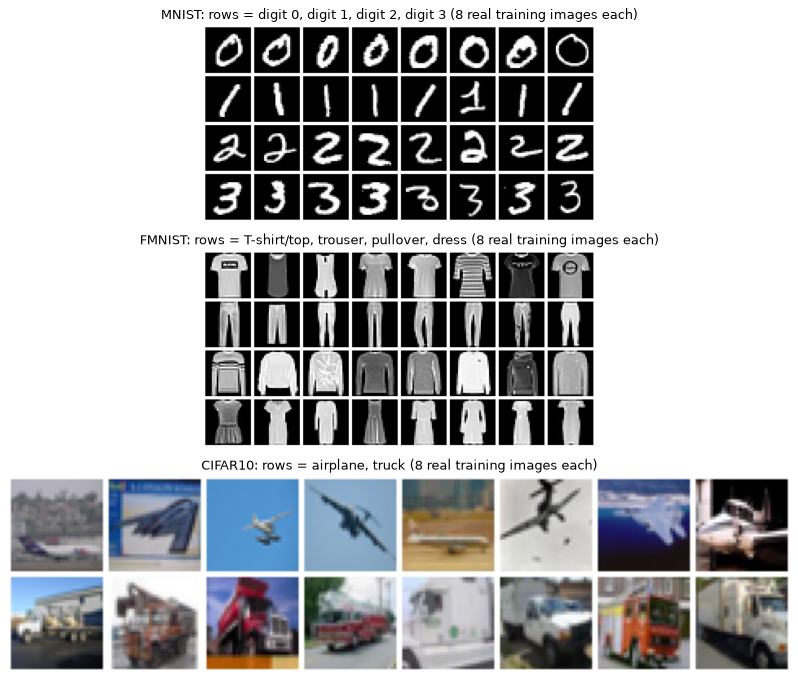

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8.6))
for ax, ds in zip(axes, ["MNIST", "FMNIST", "CIFAR10"]):
    dtr = load_parquet(ds, "train", DATA_DIR, HF_TOKEN)
    tiles = []
    for c in USED[ds]:
        sub = dtr[dtr["label"] == c].iloc[:8]
        row = [np.asarray(decode(x, "RGB" if ds == "CIFAR10" else "L")) for x in sub["image"]]
        tiles.append(np.concatenate([np.pad(r, [(1, 1), (1, 1)] + ([(0, 0)] if r.ndim == 3 else []), constant_values=255) for r in row], axis=1))
    ax.imshow(np.concatenate(tiles, axis=0), cmap="gray"); ax.axis("off"); ax.grid(False)
    ax.set_title(f"{ds}: rows = " + ", ".join(ALL_NAMES[ds][c] for c in USED[ds]) + " (8 real training images each)")
plt.tight_layout(); plt.show()

### D3. Two-dimensional view of the real observations, coloured by ground-truth label

PCA is fitted on the **training subset only**; the test points are projected with the same fit (crosses). Top row: the raw features (16x16 pixels, or the 576 HOG numbers). Bottom row: the same features **L2-normalised**, which is exactly the vector that the amplitude encoder loads into the circuit (the zero padding adds nothing). The model uses amplitude encoding, not angle encoding, so no $[0,\pi]$ rescaling exists; the second row is its counterpart. For MNIST and Fashion-MNIST all four classes of the four-class task are shown (the binary task is the subset of the first two colours).

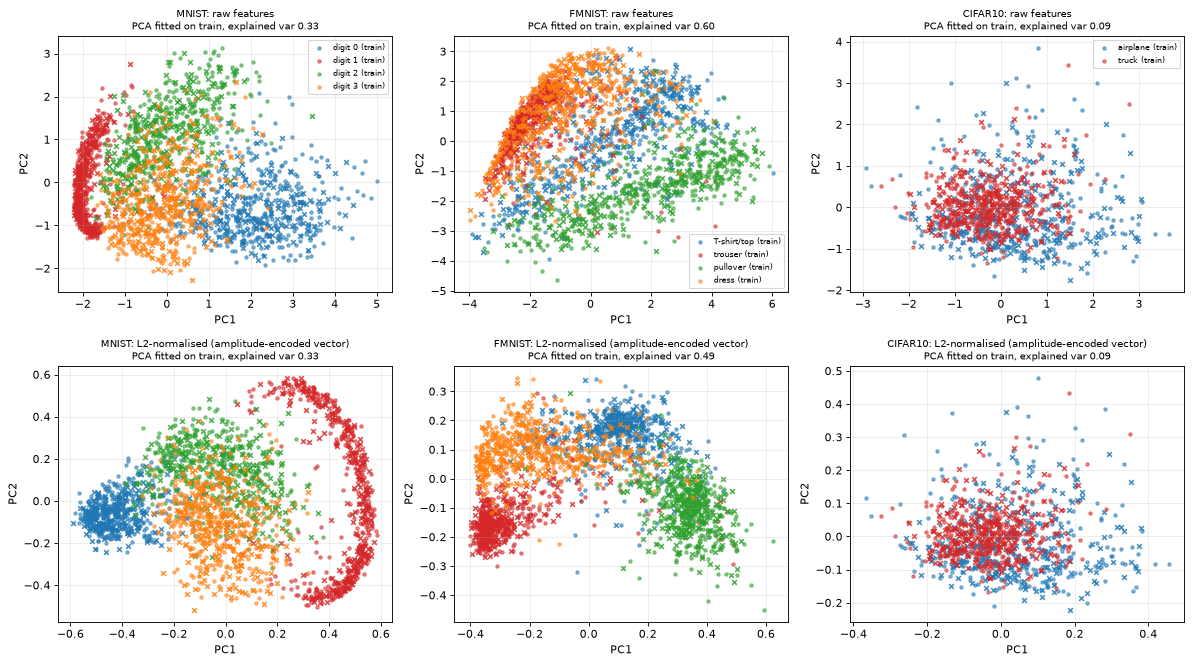

In [10]:
PAL = {0: "#1f77b4", 1: "#d62728", 2: "#2ca02c", 3: "#ff7f0e", 9: "#d62728"}
fig, axes = plt.subplots(2, 3, figsize=(15, 8.4))
for j, (ds, task) in enumerate([("MNIST", "4c"), ("FMNIST", "4c"), ("CIFAR10", "cifar2")]):
    D = DATA[(ds, task)]
    for i, (name, f) in enumerate([("raw features", lambda X: X), ("L2-normalised (amplitude-encoded vector)", lambda X: X / np.linalg.norm(X, axis=1, keepdims=True))]):
        Ftr, Fte = f(D["Xtr"]), f(D["Xte"])
        pca = PCA(n_components=2, random_state=SEED).fit(Ftr)
        Ztr, Zte = pca.transform(Ftr), pca.transform(Fte)
        ax = axes[i, j]
        for c in USED[ds]:
            m = D["ytr_orig"] == c; ax.scatter(Ztr[m, 0], Ztr[m, 1], s=9, alpha=0.55, color=PAL[c], label=f"{ALL_NAMES[ds][c]} (train)")
            m = D["yte_orig"] == c; ax.scatter(Zte[m, 0], Zte[m, 1], s=18, marker="x", color=PAL[c], alpha=0.8)
        ax.set_title(f"{ds}: {name}\nPCA fitted on train, explained var {pca.explained_variance_ratio_.sum():.2f}", fontsize=9)
        ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
        if i == 0: ax.legend(fontsize=7, loc="best")
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The figures below are drawn by `qml.draw_mpl` from the **same `make_qnode` function that was just asserted equal to the simulator**, i.e. from the PennyLane circuit that computes exactly what is trained and attacked. To keep each drawing readable the number of repeated layers is reduced to two classifier layers and one adversarial layer (the layers are identical copies; the architectures at full depth are summarised in the table after the figures, with qubit count, depth and trainable-parameter count taken from `qml.specs` of the full-depth QNodes). Rotation angles are not printed (they are the trainable parameters).

Assumptions where the paper omits circuit details: the `Rot` gate is PennyLane's $RZ(\omega)RY(\theta)RZ(\phi)$ (same gate family as the paper's); the CNOT ring is applied in the order $1\to2, 2\to3,\dots,n\to1$; the controlled-phase gate of an adversarial layer is `qml.CRZ` between neighbouring qubits of the block in a cyclic ring (control $i$, target $i+1$); the block is placed after classifier layer $q$ (for $q=0$ it acts on the encoded input); local blocks act on qubits 3,4,5 or 5,6,7,8 (1-indexed from the top wire).

### A1. Binary classifier, 9 qubits (8 data + 1 ancilla measured), global adversarial layer after layer 1

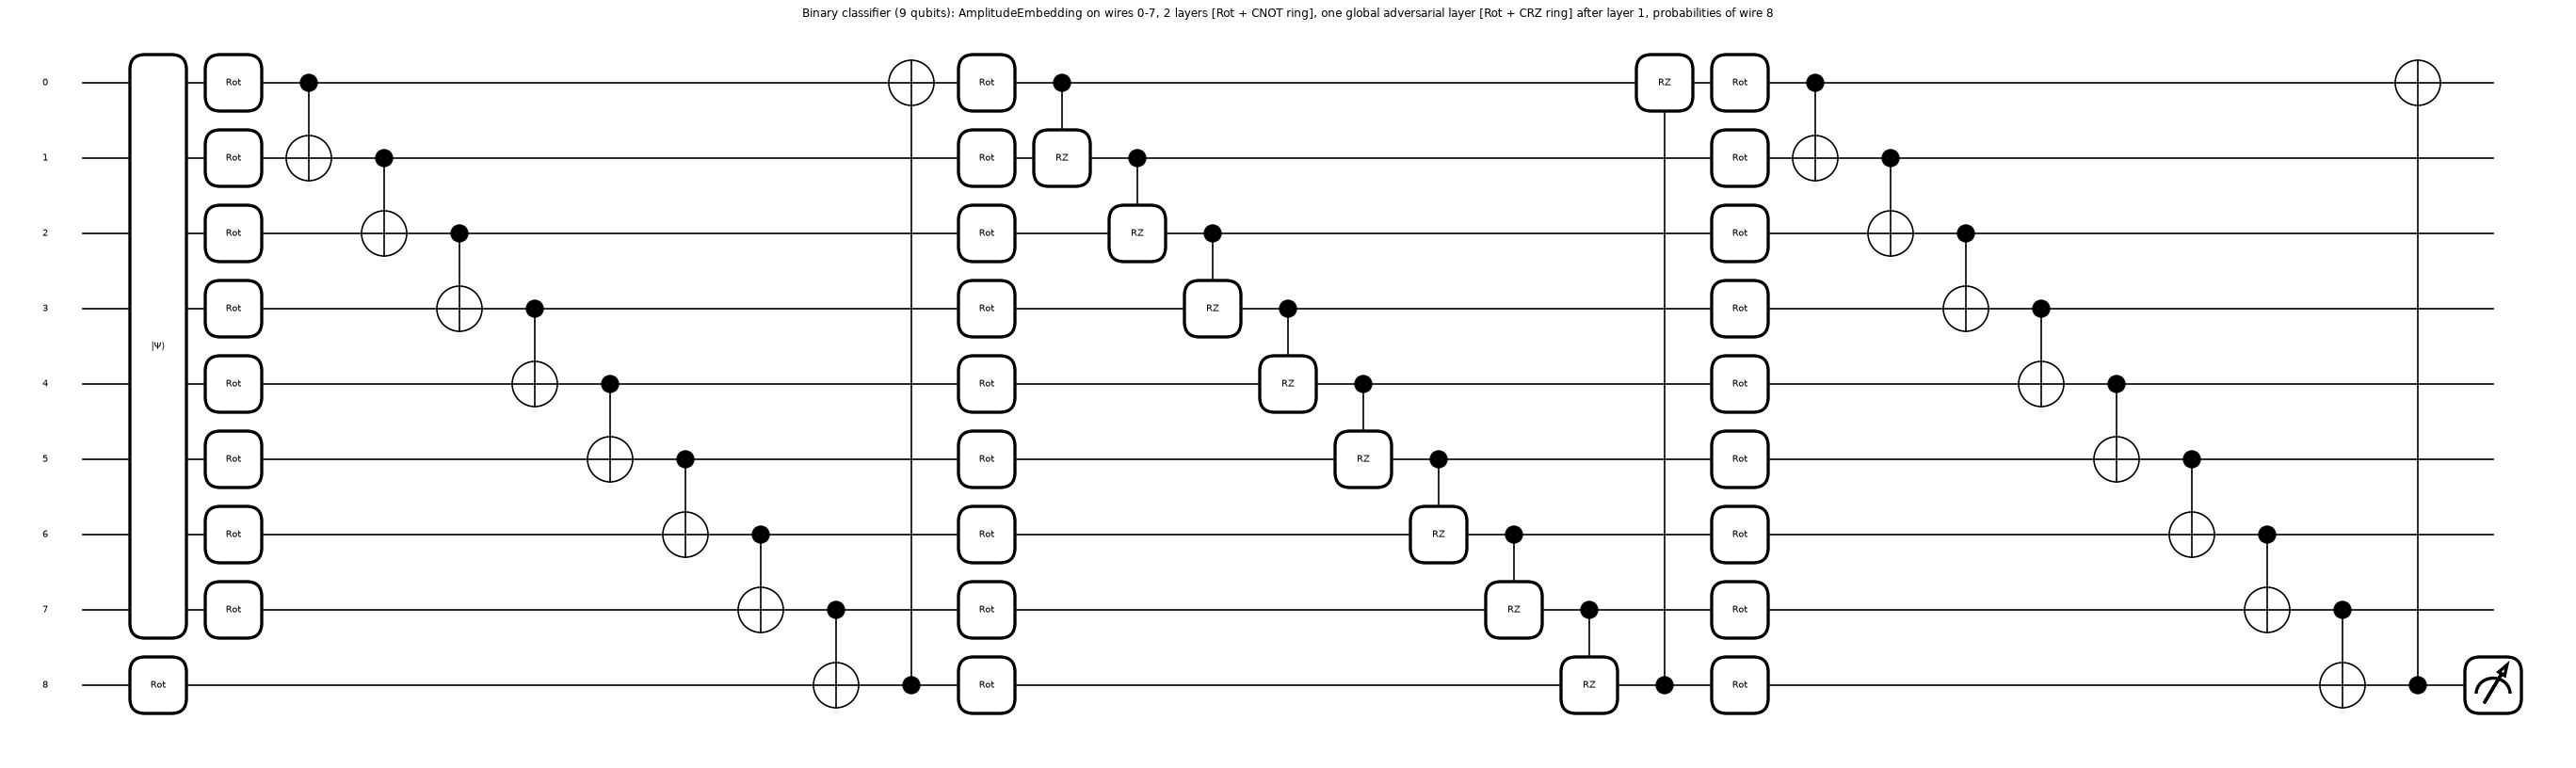

In [11]:
def draw_arch(n, d, L, blocks_spec, title, seed=1):
    g = torch.Generator().manual_seed(seed)
    w = torch.randn(L, n, 3, generator=g).numpy().astype(float)
    bl = []
    for (pos, qubits, La) in blocks_spec:
        qs = list(range(n)) if qubits is None else list(qubits)
        bl.append((pos, qs, 0.5 * torch.randn(La, len(qs), 4, generator=g).numpy().astype(float)))
    circ = make_qnode(n, d, L, w, bl)
    x = np.random.default_rng(seed).random(2 ** d - 5)
    fig, ax = qml.draw_mpl(circ, decimals=None, fontsize=9)(x)
    fig.suptitle(title, y=1.0, fontsize=11); plt.show()
    return circ

_ = draw_arch(9, 8, 2, [(1, None, 1)], "Binary classifier (9 qubits): AmplitudeEmbedding on wires 0-7, 2 layers [Rot + CNOT ring], one global adversarial layer [Rot + CRZ ring] after layer 1, probabilities of wire 8")

### A2. The same classifier with a local (3-qubit, qubits 3,4,5) adversarial layer

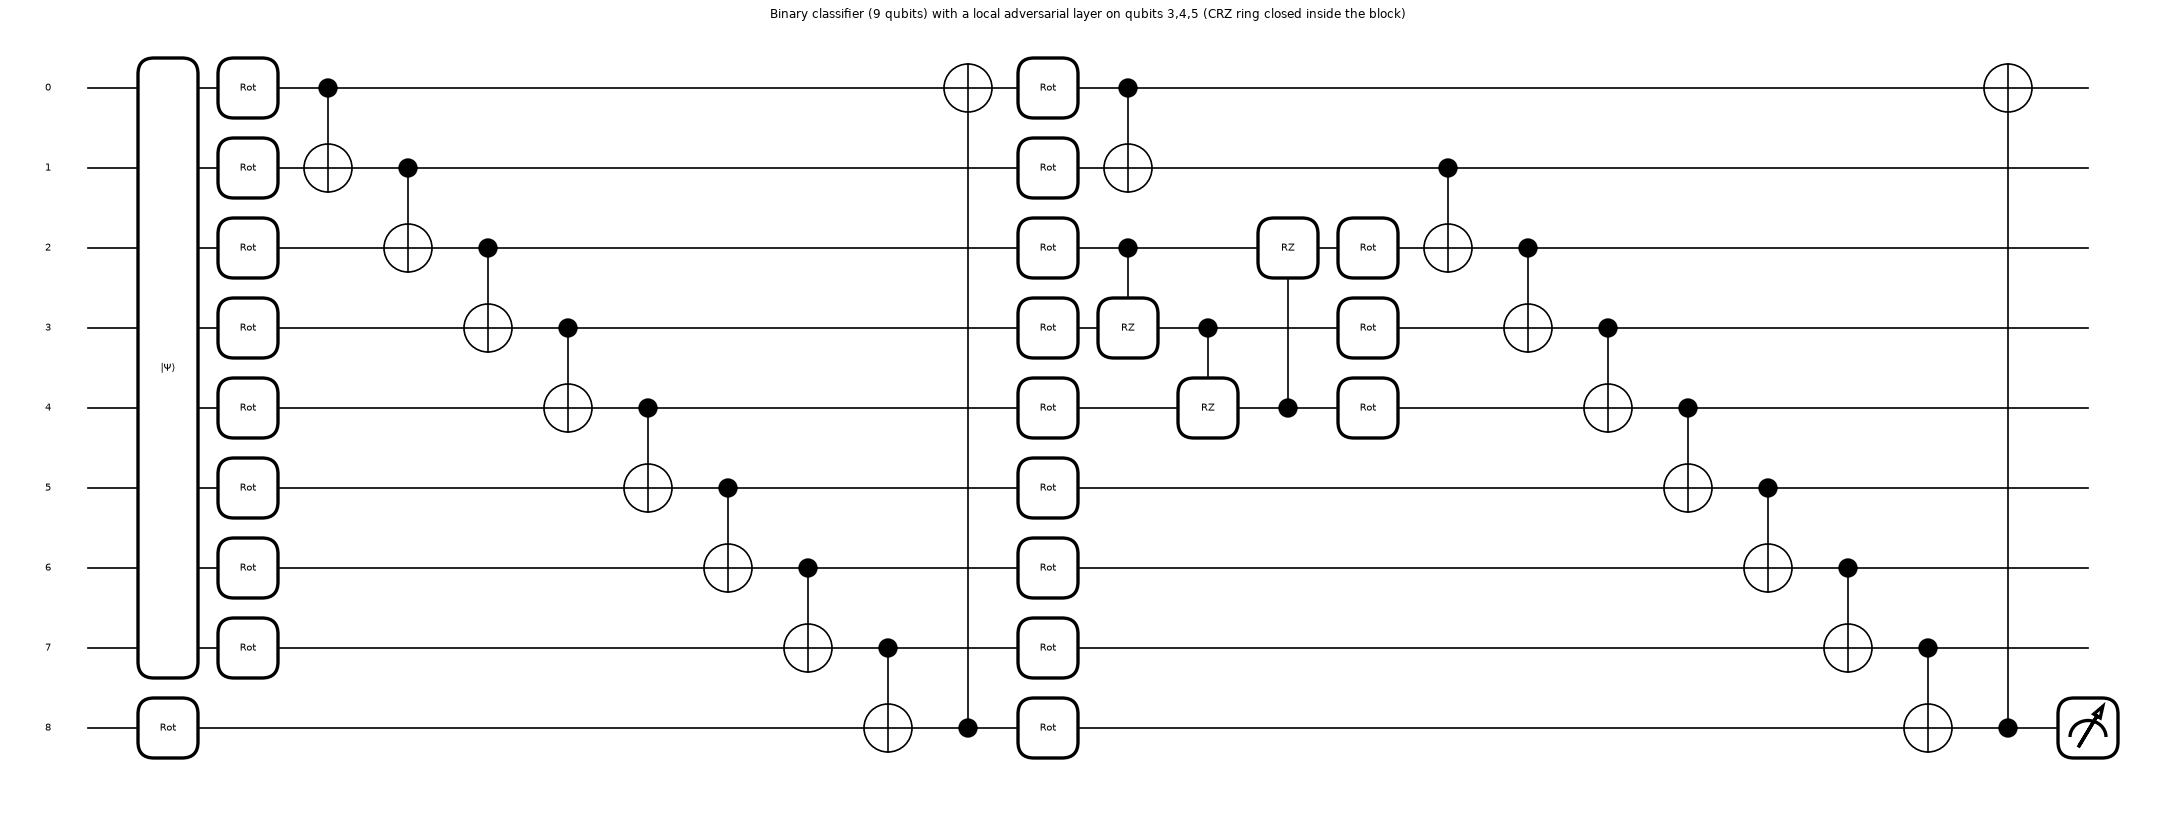

In [12]:
_ = draw_arch(9, 8, 2, [(1, [2, 3, 4], 1)], "Binary classifier (9 qubits) with a local adversarial layer on qubits 3,4,5 (CRZ ring closed inside the block)")

### A3. Four-class classifier, 10 qubits (8 data + 2 ancillas measured), global adversarial layer

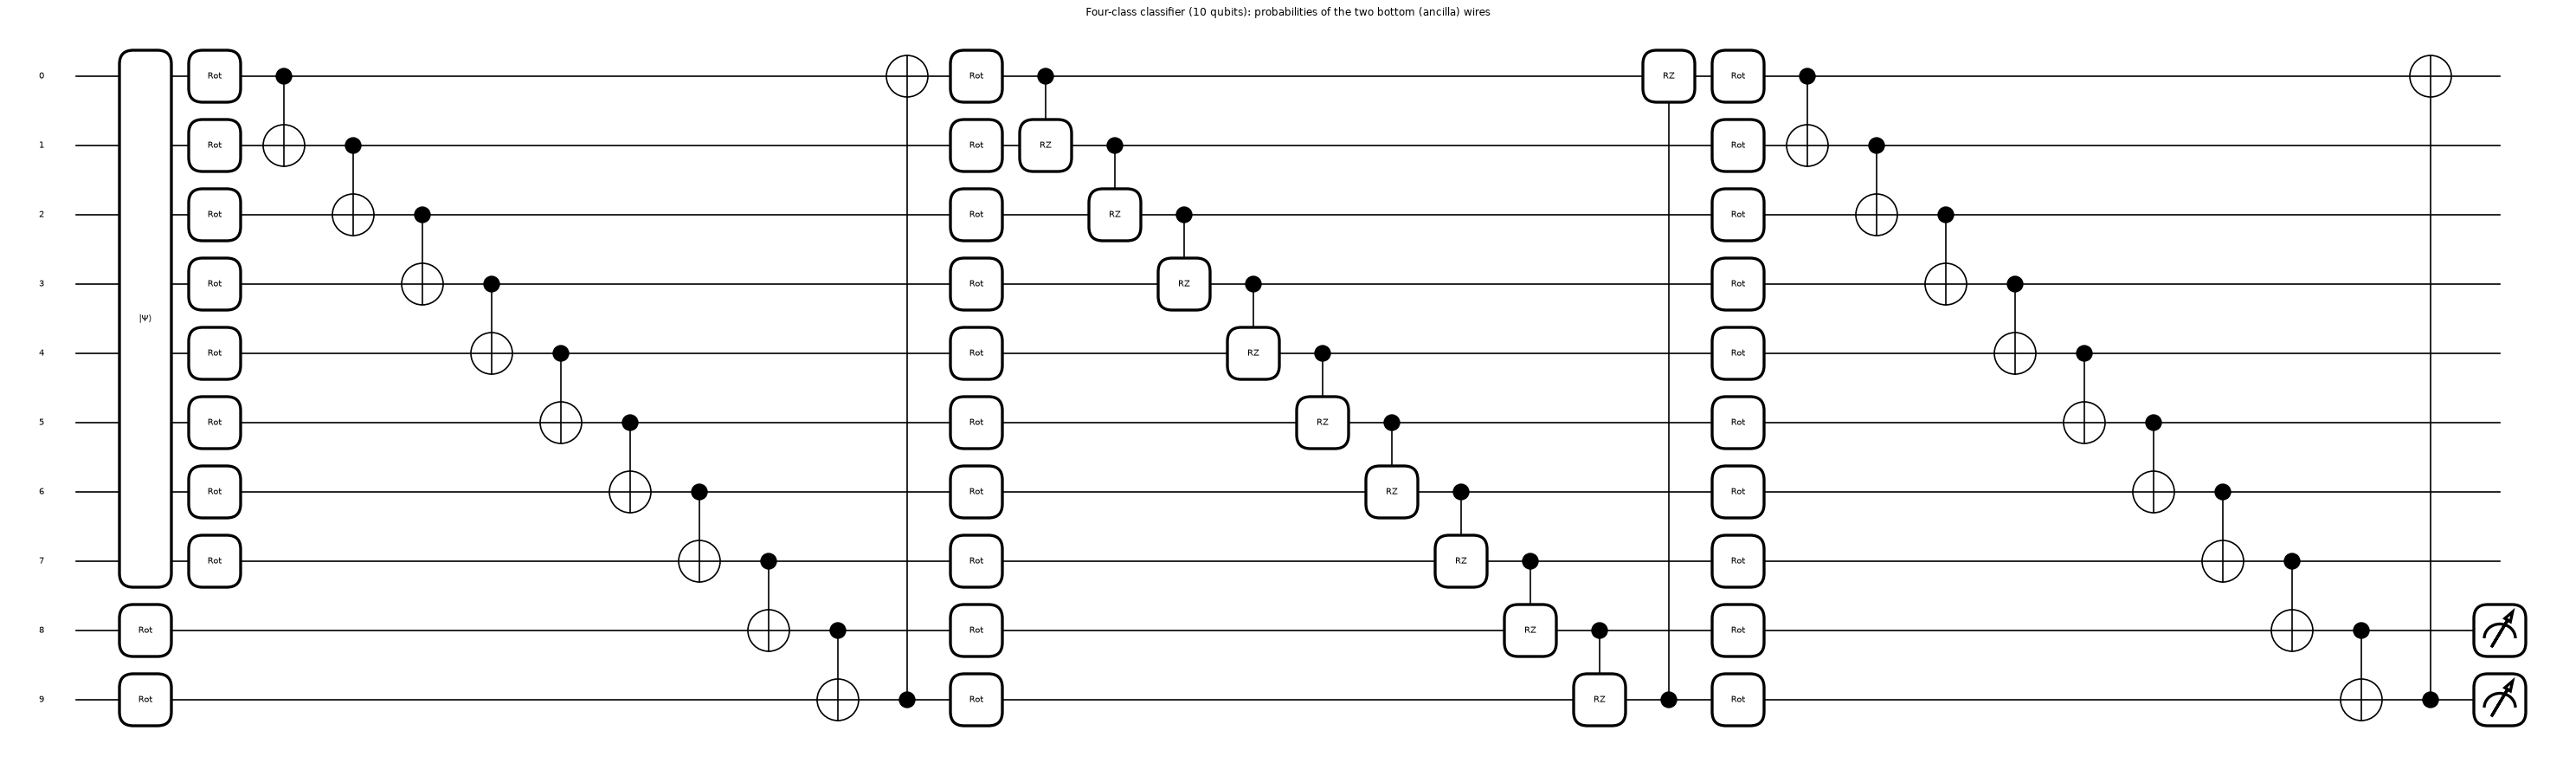

In [13]:
_ = draw_arch(10, 8, 2, [(1, None, 1)], "Four-class classifier (10 qubits): probabilities of the two bottom (ancilla) wires")

### A4. CIFAR-2 classifier, 11 qubits (10 data + 1 ancilla), global adversarial layer

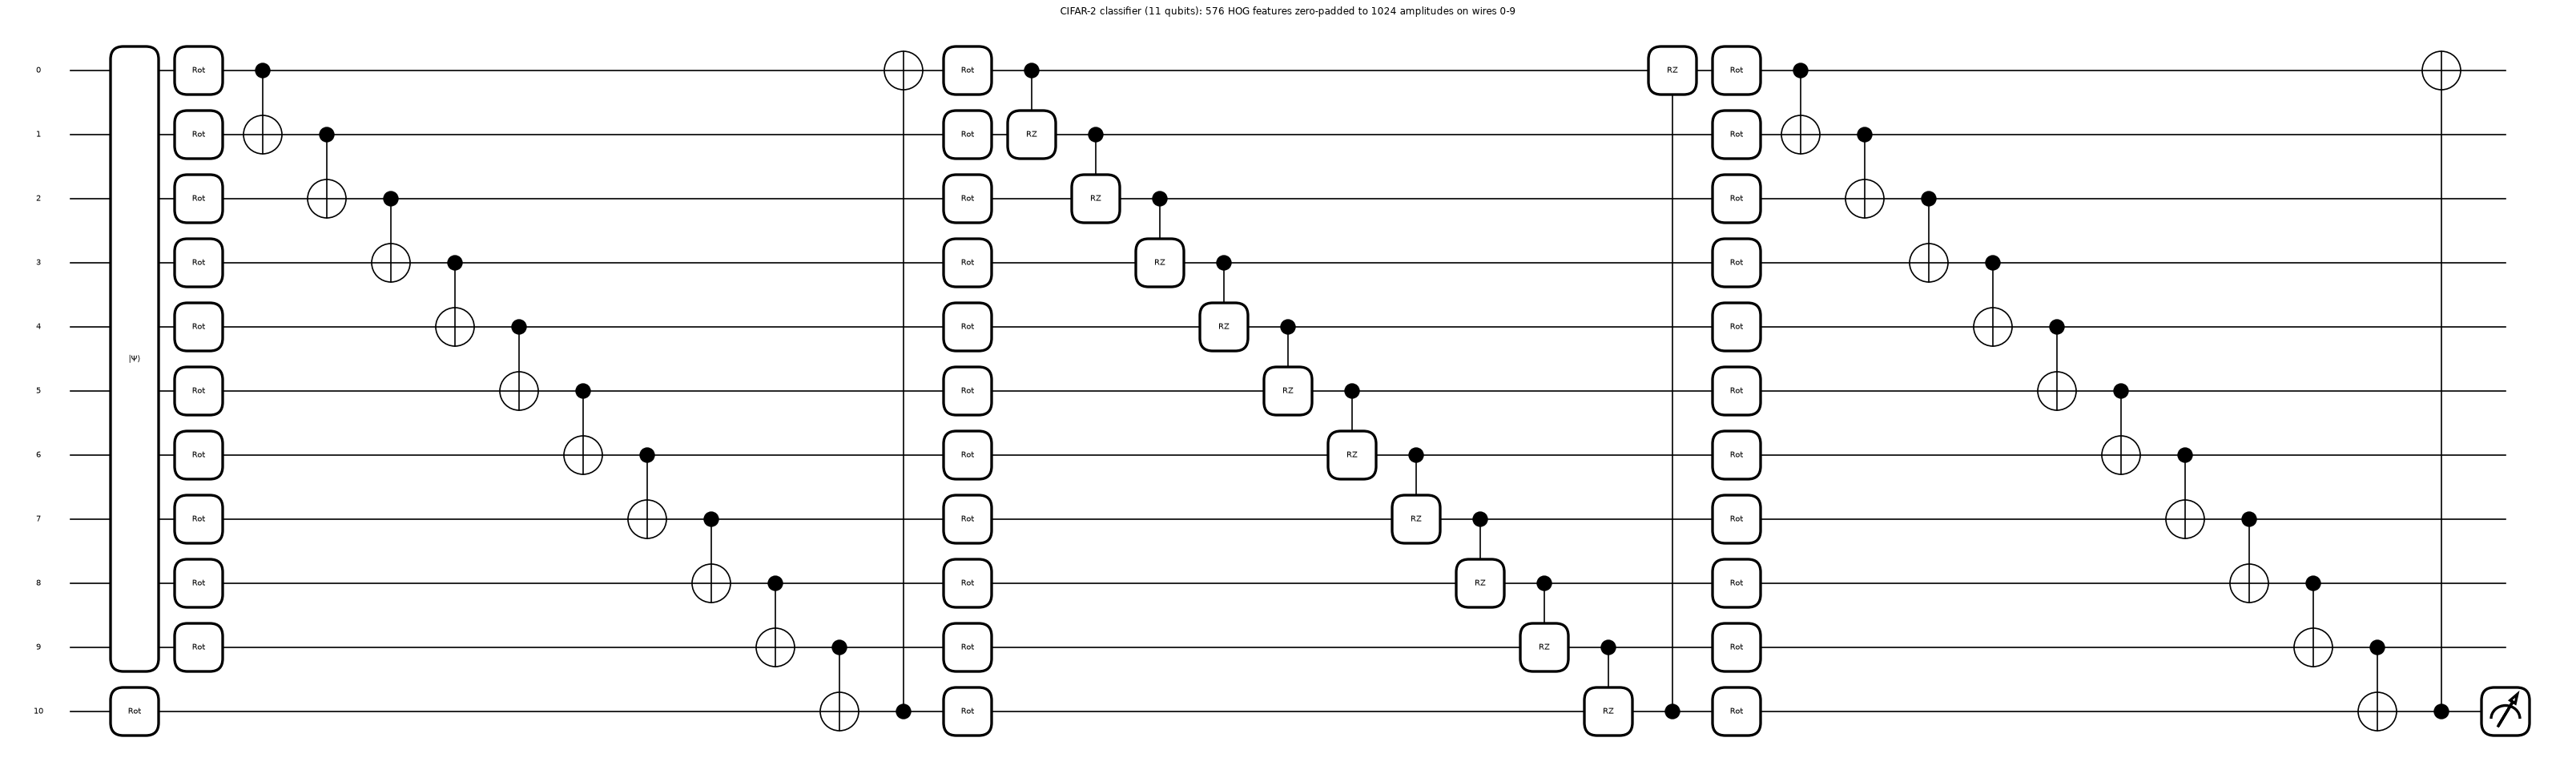

In [14]:
_ = draw_arch(11, 10, 2, [(1, None, 1)], "CIFAR-2 classifier (11 qubits): 576 HOG features zero-padded to 1024 amplitudes on wires 0-9")

### A5. Architectures actually trained and attacked: qubits, depth and trainable parameters

Qubit count, circuit depth and gate counts come from `qml.specs` of the full-depth QNode (classifier of `L` layers with a 10-layer global adversarial block in the middle); trainable parameters: classifier $3nL$, adversarial block $4\,k\,L_{adv}$ ($k$ qubits in the block).

In [15]:
rows = []
arch_list = sorted({(task, L) for _, task, L in CLASSIFIERS}, key=lambda t: (t[0], t[1]))
for (task, L) in arch_list:
    spec = TASKS[task]; n = spec["d"] + spec["da"]; d = spec["d"]
    w = np.random.default_rng(0).normal(size=(L, n, 3))
    plain = make_qnode(n, d, L, w, [])
    att = make_qnode(n, d, L, w, [((L + 1) // 2, list(range(n)), np.random.default_rng(1).normal(size=(10, n, 4)))])
    x = np.random.default_rng(2).random(2 ** d - 5)
    s0 = qml.specs(plain)(x).resources; s1 = qml.specs(att)(x).resources
    rows.append(dict(task=task, layers=L, qubits=n, measured_wires=spec["da"], depth_classifier=s0.depth, gates_classifier=s0.num_gates,
                     depth_with_10layer_block=s1.depth, gates_with_block=s1.num_gates, params_classifier=3 * n * L,
                     params_global_block_10_layers=4 * n * 10, params_local3_block_10_layers=4 * 3 * 10))
display(pd.DataFrame(rows))

,task,layers,qubits,measured_wires,depth_classifier,gates_classifier,depth_with_10layer_block,gates_with_block,params_classifier,params_global_block_10_layers,params_local3_block_10_layers
0,4c,20,10,2,221,401,331,601,600,400,120
1,bin,10,9,1,101,181,201,361,270,360,120
2,bin,20,9,1,201,361,301,541,540,360,120
3,cifar2,80,11,1,961,1761,1081,1981,2640,440,120


## 4. Training the clean classifiers and Table 1 (paper Appendix C.2)

Training follows the paper: Adam, batch 64, cross-entropy on the measured class probabilities, learning-rate phases (binary: two phases, four-class: three, CIFAR-2: one). The epoch budgets are smaller than the paper's and the learning rates larger (configuration cell; we take far fewer optimiser steps), and the weights start from $\mathcal N(0,0.3^2)$ (the paper does not say). Accuracy is measured on the test subset. As a classical baseline an RBF-SVM and a random forest are trained on **exactly the same L2-normalised 256- or 576-dimensional inputs**.

In [16]:
PAPER_T1 = {("MNIST", "bin", 10): 99.67, ("MNIST", "bin", 20): 99.86, ("MNIST", "4c", 20): 90.40, ("MNIST", "4c", 40): 92.18,
            ("FMNIST", "bin", 10): 94.80, ("FMNIST", "bin", 20): 94.75, ("FMNIST", "4c", 20): 79.80, ("FMNIST", "4c", 40): 84.18,
            ("CIFAR10", "cifar2", 80): 83.05}

def probs_of(D, w, E, blocks=(), bs=500):
    n, d, K = D["n"], D["d"], D["K"]; lay = get_layout(n)
    with torch.no_grad():
        return torch.cat([class_probs(run(E[i:i + bs], w, lay, blocks), n, d, K) for i in range(0, len(E), bs)])

def nll(p, y):
    return -torch.log(p.gather(1, y[:, None]) + 1e-9).mean()      # cross-entropy of the measured probabilities

def train_classifier(D, task, L, seed):
    n, d, K = D["n"], D["d"], D["K"]; lay = get_layout(n)
    g = torch.Generator().manual_seed(seed)
    w = (INIT_STD * torch.randn(L, n, 3, generator=g)).requires_grad_(True)       # CHOICE: N(0, 0.3^2) initial angles
    opt = torch.optim.Adam([w], lr=1e-3)
    N = len(D["Etr"]); losses = []
    for (n_ep, lr) in EPOCHS[task]:
        for gp in opt.param_groups: gp["lr"] = lr
        for _ in range(n_ep):
            perm = torch.randperm(N, generator=g); tot = 0.0
            for i in range(0, N, CLF_BATCH):
                idx = perm[i:i + CLF_BATCH]
                loss = nll(class_probs(run(D["Etr"][idx], w, lay), n, d, K), D["Ytr"][idx])
                opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(idx)
            losses.append(tot / N)
    return w.detach(), losses

CLF = {}
for (ds, task, L) in CLASSIFIERS:
    D = DATA[(ds, task)]; t0 = time.time()
    w, losses = train_classifier(D, task, L, SEED)
    Pte = probs_of(D, w, D["Ete"]); Ptr = probs_of(D, w, D["Etr"])
    acc = (Pte.argmax(1) == D["Yte"]).float().mean().item(); acc_tr = (Ptr.argmax(1) == D["Ytr"]).float().mean().item()
    CLF[(ds, task, L)] = dict(w=w, losses=losses, Pte=Pte, acc=acc, acc_train=acc_tr, time=time.time() - t0)
    print(f"{ds:8s} {task:7s} L={L:3d}: train acc {acc_tr:.4f}  test acc {acc:.4f}  final loss {losses[-1]:.3f}  ({time.time() - t0:.0f} s)")

MNIST    bin     L= 10: train acc 0.9960  test acc 0.9980  final loss 0.410  (89 s)


MNIST    bin     L= 20: train acc 0.9955  test acc 0.9960  final loss 0.306  (136 s)


FMNIST   bin     L= 10: train acc 0.9565  test acc 0.9460  final loss 0.479  (79 s)


FMNIST   bin     L= 20: train acc 0.9565  test acc 0.9480  final loss 0.405  (153 s)


MNIST    4c      L= 20: train acc 0.9307  test acc 0.9062  final loss 1.046  (410 s)


FMNIST   4c      L= 20: train acc 0.8967  test acc 0.8800  final loss 1.096  (317 s)


CIFAR10  cifar2  L= 80: train acc 0.7969  test acc 0.8000  final loss 0.636  (419 s)


,dataset,task,layers,qubits,train/test,quantum acc %,paper acc %,gap,verdict,SVC-rbf acc %,RF acc %,quantum train+eval s,SVC s,RF s
0,MNIST,bin,10,9,2000/1000,99.80,99.67,0.13,reproduced,99.8,99.90,89.5,0.40,6.68
1,MNIST,bin,20,9,2000/1000,99.60,99.86,-0.26,reproduced,99.8,99.90,135.8,0.40,6.68
2,FMNIST,bin,10,9,2000/1000,94.60,94.80,-0.20,reproduced,97.7,97.40,79.0,0.69,9.69
3,FMNIST,bin,20,9,2000/1000,94.80,94.75,0.05,reproduced,97.7,97.40,153.4,0.69,9.69
4,MNIST,4c,20,10,1500/800,90.62,90.40,0.22,reproduced,99.0,98.12,410.1,1.05,10.17
5,FMNIST,4c,20,10,1500/800,88.00,79.80,8.20,exceeded,91.0,92.12,317.5,1.16,12.93
6,CIFAR10,cifar2,80,11,640/400,80.00,83.05,-3.05,not reached,86.5,84.50,419.3,1.70,6.73


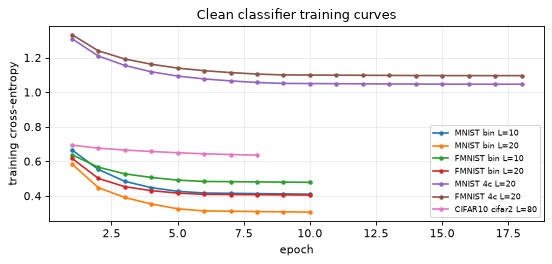

In [17]:
BASE = {}
for (ds, task) in sorted({(a, b) for a, b, _ in CLASSIFIERS}):
    D = DATA[(ds, task)]
    Xa = D["Xtr"] / np.linalg.norm(D["Xtr"], axis=1, keepdims=True); Xb = D["Xte"] / np.linalg.norm(D["Xte"], axis=1, keepdims=True)
    t0 = time.time(); svc = SVC(kernel="rbf", C=1.0, gamma="scale").fit(Xa, D["ytr"]); a_svc = svc.score(Xb, D["yte"]); t_svc = time.time() - t0
    t0 = time.time(); rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1).fit(Xa, D["ytr"]); a_rf = rf.score(Xb, D["yte"]); t_rf = time.time() - t0
    BASE[(ds, task)] = dict(svc=a_svc, rf=a_rf, t_svc=t_svc, t_rf=t_rf)

def verdict_acc(nb, paper, tol=2.0):
    if abs(nb - paper) <= tol: return "reproduced"
    return "exceeded" if nb > paper else "not reached"

rows = []
for (ds, task, L) in CLASSIFIERS:
    D = DATA[(ds, task)]; C = CLF[(ds, task, L)]; B = BASE[(ds, task)]
    paper = PAPER_T1.get((ds, task, L))
    rows.append({"dataset": ds, "task": task, "layers": L, "qubits": D["n"], "train/test": f"{len(D['Ytr'])}/{len(D['Yte'])}",
                 "quantum acc %": round(100 * C["acc"], 2), "paper acc %": paper,
                 "gap": None if paper is None else round(100 * C["acc"] - paper, 2),
                 "verdict": None if paper is None else verdict_acc(100 * C["acc"], paper),
                 "SVC-rbf acc %": round(100 * B["svc"], 2), "RF acc %": round(100 * B["rf"], 2),
                 "quantum train+eval s": round(C["time"], 1), "SVC s": round(B["t_svc"], 2), "RF s": round(B["t_rf"], 2)})
TABLE1 = pd.DataFrame(rows)
display(TABLE1)

fig, ax = plt.subplots(1, 1, figsize=(7, 3.4))
for (ds, task, L), C in CLF.items():
    ax.plot(range(1, len(C["losses"]) + 1), C["losses"], marker="o", ms=3, label=f"{ds} {task} L={L}")
ax.set_xlabel("epoch"); ax.set_ylabel("training cross-entropy"); ax.set_title("Clean classifier training curves"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 5. The adversary: trainable gates planted inside the circuit (paper Appendix C.3.1)

* An **adversarial layer** has the structure of a classifier layer, with the CNOT ring replaced by a ring of CRZ$(\varphi)$ gates: three rotation angles per qubit and one controlled-phase angle per qubit, i.e. $4\,k\,L_{adv}$ parameters for a block of $L_{adv}$ layers on $k$ qubits. All parameters start at 0, so the block starts as the identity gate.
* A **scenario** says where blocks sit and how many qubits they touch. Position `input` = before the first layer (the usual input-state attack); `q1`, `q2`, `q3` = after layer $\lceil \ell/4\rceil$, $\lceil \ell/2\rceil$, $\lceil 3\ell/4\rceil$ (what a tampered wire cut or teleportation in the middle of the circuit can do); `3x(3,3,4)` and `3x10` = three blocks at q1, q2, q3 with 3+3+4 or 10+10+10 layers. `g:` = global (all qubits), `l3:` = qubits 3,4,5, `l4:` = qubits 5,6,7,8.
* The classifier stays frozen (white box). The block parameters are trained by SGD to **maximise** the cross-entropy ($\gamma=0$ in Eq. 35). After every epoch we record on the test subset: the misclassification rate, the mean probability of the true class, and the **attack strength** $\sum_i \|\hat U_i-I\|_2/\sqrt{2^{k}}$ where $\hat U_i$ is the $2^k\times 2^k$ unitary of block $i$, obtained by pushing all basis states through it.
* Along the way we also record what Theorem 6.3 predicts (see section 7).

In [18]:
def block_unitary(a):
    # the 2^k x 2^k unitary of an adversarial block on its own k qubits: push every basis state through it (column b = U|b>)
    k = a.shape[1]
    with torch.no_grad():
        out = adversarial_layers(torch.eye(2 ** k, dtype=CDT), a, get_layout(k))
    return out.T

def unit_strength(a):
    U = block_unitary(a); k = a.shape[1]
    return ((U - torch.eye(2 ** k, dtype=CDT)).abs() ** 2).sum().sqrt().item() / math.sqrt(2 ** k)     # normalised Hilbert-Schmidt distance

def parse_scenario(scen, L):
    scope, spec = scen.split(":")
    qubits = {"g": None, "l3": (2, 3, 4), "l4": (4, 5, 6, 7)}[scope]
    q1, q2, q3 = math.ceil(L / 4), math.ceil(L / 2), math.ceil(3 * L / 4)
    pos = {"q1": q1, "q2": q2, "q3": q3}
    if spec == "input": blocks = [(0, 10)]
    elif spec in pos: blocks = [(pos[spec], 10)]
    elif spec.startswith("q2@"): blocks = [(q2, int(spec[3:]))]
    elif spec == "3x(3,3,4)": blocks = [(q1, 3), (q2, 3), (q3, 4)]
    elif spec == "3x10": blocks = [(q1, 10), (q2, 10), (q3, 10)]
    else: raise ValueError(scen)
    return qubits, blocks

def scen_label(scen, L):
    scope, spec = scen.split(":"); q = {"q1": math.ceil(L / 4), "q2": math.ceil(L / 2), "q3": math.ceil(3 * L / 4)}
    pre = {"g": "", "l3": "local-3 ", "l4": "local-4 "}[scope]
    if spec == "input": return pre + "input layer"
    if spec in q: return pre + f"after layer {q[spec]}"
    if spec.startswith("q2@"): return pre + f"after layer {q['q2']}, {spec[3:]} adv. layers"
    return pre + {"3x(3,3,4)": f"3 blocks [3,3,4] after layers {q['q1']},{q['q2']},{q['q3']}", "3x10": f"3 blocks [10,10,10] after layers {q['q1']},{q['q2']},{q['q3']}"}[spec]

def run_attack(ds, task, L, scen, seed):
    D = DATA[(ds, task)]; C = CLF[(ds, task, L)]; w = C["w"]; n, d, K = D["n"], D["d"], D["K"]
    qubits, bspec = parse_scenario(scen, L)
    lay, blay = get_layout(n), get_layout(n, qubits); k = n if qubits is None else len(qubits)
    params = [torch.zeros(La, k, 4, requires_grad=True) for (_, La) in bspec]            # all zero = identity gates
    opt = torch.optim.SGD(params, lr=ADV_LR[task] if task in ADV_LR else ADV_LR[ds])                                           # CHOICE: lr = 10x the paper's (fewer steps)
    g = torch.Generator().manual_seed(seed)
    Ytrue = D["Yte"][:, None]; Pc_true = C["Pte"].gather(1, Ytrue)[:, 0]
    blocks_of = lambda ps: [(pos, a, blay) for (pos, _), a in zip(bspec, ps)]
    def snapshot():
        ps = [p.detach() for p in params]
        ss = [unit_strength(a) for a in ps]
        P = probs_of(D, w, D["Ete"], blocks_of(ps)); pt = P.gather(1, Ytrue)[:, 0]
        s2 = sum(v ** 2 for v in ss)
        rec = dict(strength=sum(ss), s2=s2, mis=(P.argmax(1) != D["Yte"]).float().mean().item(), ptrue=pt.mean().item())
        for c in CONFS:       # Theorem 6.3 half-width at confidence c, constants as in the CHOICE row of the table above
            delta = math.sqrt(4 * 2 ** d * s2 / ((2 ** n + 1) * (1 - c)))
            rec[f"delta{int(round(c * 100))}"] = delta
            rec[f"cov{int(round(c * 100))}"] = ((pt - Pc_true).abs() < delta).float().mean().item()
        return rec, P, ps
    hist = [snapshot()[0]]
    N = len(D["Etr"])
    for ep in range(ADV_EPOCHS[task]):
        perm = torch.randperm(N, generator=g)
        for i in range(0, N, ADV_BATCH):
            idx = perm[i:i + ADV_BATCH]
            p = class_probs(run(D["Etr"][idx], w, lay, blocks_of(params)), n, d, K)
            loss = nll(p, D["Ytr"][idx])
            opt.zero_grad(); (-loss).backward(); opt.step()                                # gradient ASCENT on the cross-entropy
        rec, P, ps = snapshot(); hist.append(rec)
    return dict(hist=hist, params=ps, P_final=P, qubits=qubits, bspec=bspec)

def plan_jobs():
    jobs = []
    for (ds, task, L) in CLASSIFIERS:
        if task == "bin" and L == 10: scens = SCEN_MAIN
        elif task == "cifar2": scens = (["g:q2"] if FAST_MODE else ["g:input", "g:q2"]) + (["g:q2@40"] if CIFAR_LONG_BLOCK else [])
        else: scens = SCEN_MIN
        for s in scens:
            for sd in (SEEDS_KEY if (task == "bin" and L == 10 and s in ("g:input", "g:q2")) else [SEED]):
                jobs.append((ds, task, L, s, sd))
    return jobs
JOBS = plan_jobs()
print(len(JOBS), "attack runs planned")

34 attack runs planned


### 5.1 Run all attacks

Each run prints the final misclassification rate and attack strength. Epoch 0 of every curve is the clean model (strength 0).

In [19]:
RES = {}
t_all = time.time()
for i, job in enumerate(JOBS):
    t0 = time.time(); ds, task, L, scen, sd = job
    RES[job] = run_attack(*job)
    h = RES[job]["hist"]
    print(f"[{i + 1:2d}/{len(JOBS)}] {ds:8s} {task:6s} L={L:2d} {scen_label(scen, L):<48s} seed {sd}: "
          f"misclassification {100 * h[0]['mis']:5.1f}% -> {100 * h[-1]['mis']:5.1f}%  strength {h[-1]['strength']:.2f}  ({time.time() - t0:.0f} s)", flush=True)
print(f"all attacks done in {(time.time() - t_all) / 60:.1f} min")

[ 1/34] MNIST    bin    L=10 input layer                                      seed 42: misclassification   0.2% ->  95.0%  strength 1.20  (77 s)


[ 2/34] MNIST    bin    L=10 input layer                                      seed 43: misclassification   0.2% ->  95.5%  strength 1.20  (68 s)


[ 3/34] MNIST    bin    L=10 after layer 3                                    seed 42: misclassification   0.2% ->  98.7%  strength 1.35  (71 s)


[ 4/34] MNIST    bin    L=10 after layer 5                                    seed 42: misclassification   0.2% ->  98.7%  strength 1.31  (73 s)


[ 5/34] MNIST    bin    L=10 after layer 5                                    seed 43: misclassification   0.2% ->  98.4%  strength 1.34  (101 s)


...

[31/34] FMNIST   4c     L=20 input layer                                      seed 42: misclassification  12.0% ->  96.9%  strength 1.36  (106 s)


[32/34] FMNIST   4c     L=20 after layer 10                                   seed 42: misclassification  12.0% ->  97.6%  strength 1.35  (108 s)


[33/34] CIFAR10  cifar2 L=80 input layer                                      seed 42: misclassification  20.0% ->  56.0%  strength 1.25  (257 s)


[34/34] CIFAR10  cifar2 L=80 after layer 40                                   seed 42: misclassification  20.0% ->  44.2%  strength 1.29  (287 s)


all attacks done in 59.4 min


## 6. Misclassification rate versus attack strength (paper Figures 8-22)

Each curve is one scenario; the markers are the epochs (the first marker is the clean model). Where several seeds were run, the line is their mean and the band their standard deviation. As in the paper, strengths are summed over blocks, so three-block attacks reach larger strengths.

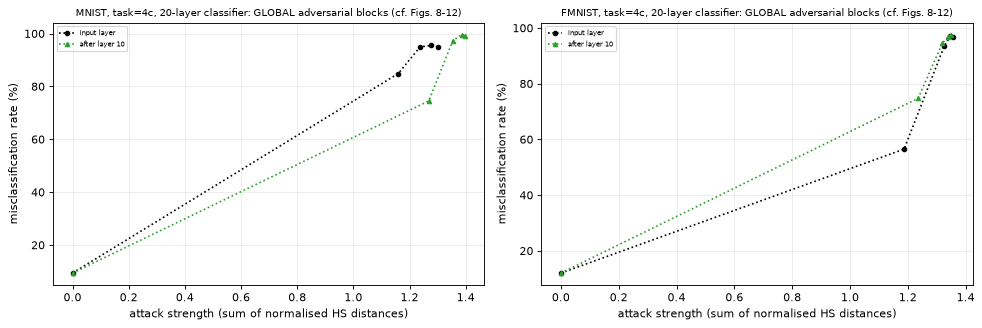

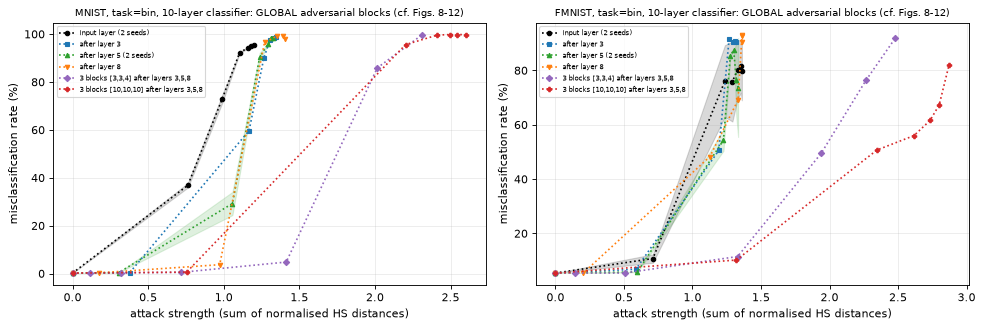

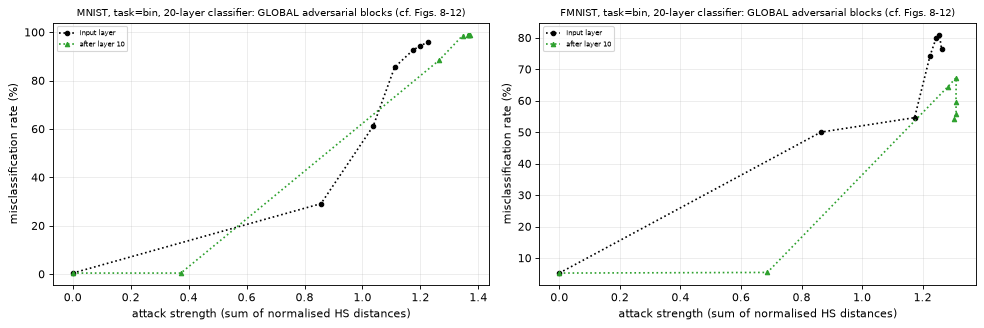

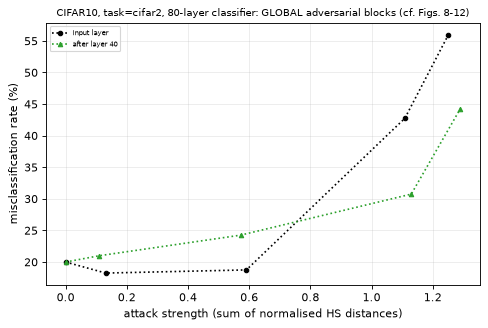

In [20]:
def curve(ds, task, L, scen):
    runs = [RES[k]["hist"] for k in RES if k[:4] == (ds, task, L, scen)]
    x = np.mean([[r["strength"] for r in h] for h in runs], 0); y = np.mean([[r["mis"] for r in h] for h in runs], 0)
    sd = np.std([[r["mis"] for r in h] for h in runs], 0)
    return x, y, sd, len(runs)

STYLE = {"input": ("k", "o"), "q1": ("tab:blue", "s"), "q2": ("tab:green", "^"), "q3": ("tab:orange", "v"), "3x(3,3,4)": ("tab:purple", "D"),
         "3x10": ("tab:red", "P"), "q2@40": ("tab:brown", "X")}
def plot_scenarios(ax, ds, task, L, scens, title):
    for scen in scens:
        if (ds, task, L) not in CLF or not any(k[:4] == (ds, task, L, scen) for k in RES): continue
        x, y, sd, ns = curve(ds, task, L, scen)
        col, mk = STYLE[scen.split(":")[1]]
        ls = {"g": ":", "l3": "--", "l4": "-."}[scen.split(":")[0]]
        ax.plot(x, 100 * y, marker=mk, ls=ls, color=col, ms=4, label=scen_label(scen, L) + (f" ({ns} seeds)" if ns > 1 else ""))
        if ns > 1: ax.fill_between(x, 100 * (y - sd), 100 * (y + sd), color=col, alpha=0.15)
    ax.set_title(title, fontsize=9); ax.set_xlabel("attack strength (sum of normalised HS distances)"); ax.set_ylabel("misclassification rate (%)")
    ax.legend(fontsize=6.5)

GROUPS = sorted({(task, L) for _, task, L in CLASSIFIERS}, key=lambda t: (t[0], t[1]))
for (task, L) in GROUPS:
    dss = [ds for ds in ("MNIST", "FMNIST", "CIFAR10") if (ds, task, L) in CLF]
    fig, axes = plt.subplots(1, len(dss), figsize=(6.2 * len(dss), 4.2), squeeze=False)
    for ax, ds in zip(axes[0], dss):
        glob = [s for s in ["g:input", "g:q1", "g:q2", "g:q3", "g:3x(3,3,4)", "g:3x10", "g:q2@40"]]
        plot_scenarios(ax, ds, task, L, glob, f"{ds}, task={task}, {L}-layer classifier: GLOBAL adversarial blocks (cf. Figs. 8-12)")
    plt.tight_layout(); plt.show()

### 6.1 Local adversarial gates (paper Figures 13-22) next to the global block at the same position

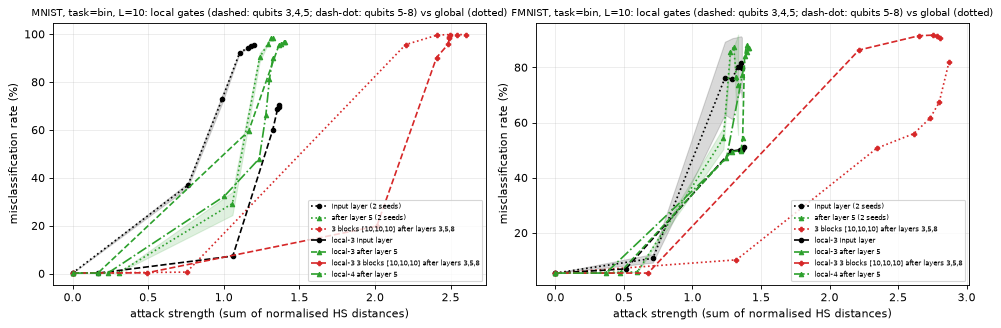

In [21]:
local_groups = [(task, L) for (task, L) in GROUPS if any(k[:3] == (ds, task, L) and k[3].startswith("l") for k in RES for ds in ("MNIST", "FMNIST"))]
if not local_groups:
    print("no local-gate runs in this configuration")
for (task, L) in local_groups:
    dss = [ds for ds in ("MNIST", "FMNIST") if (ds, task, L) in CLF]
    fig, axes = plt.subplots(1, len(dss), figsize=(6.2 * len(dss), 4.2), squeeze=False)
    for ax, ds in zip(axes[0], dss):
        plot_scenarios(ax, ds, task, L, ["g:input", "g:q2", "g:3x10", "l3:input", "l3:q2", "l3:3x10", "l4:q2"],
                       f"{ds}, task={task}, L={L}: local gates (dashed: qubits 3,4,5; dash-dot: qubits 5-8) vs global (dotted)")
    plt.tight_layout(); plt.show()

### 6.2 Reading the curves quantitatively

The paper compares curves by eye. To turn "scenario A is more successful than B at a given attack strength" into a number we average each curve's misclassification rate over the **common range of attack strengths** $[0,s_{\max}]$ (the largest strength reached by *both* curves), by linear interpolation. The difference A minus B is reported in percentage points.

In [22]:
def mean_mis(ds, task, L, scen, s_max, npts=60):
    x, y, _, _ = curve(ds, task, L, scen)
    x = np.maximum.accumulate(x)
    grid = np.linspace(0, s_max, npts)
    return 100 * float(np.mean(np.interp(grid, x, y)))

def have(ds, task, L, scen):
    return any(k[:4] == (ds, task, L, scen) for k in RES)

def advantage(ds, task, L, a, b):
    # mean misclassification (percentage points) of scenario a minus scenario b over their common strength range
    xa, xb = curve(ds, task, L, a)[0], curve(ds, task, L, b)[0]
    s_max = min(xa.max(), xb.max())
    return mean_mis(ds, task, L, a, s_max) - mean_mis(ds, task, L, b, s_max), s_max

CMP = []   # one row per comparison, reused by the final verdict table
def compare(claim, ds, task, L, a, b):
    if have(ds, task, L, a) and have(ds, task, L, b):
        adv, s_max = advantage(ds, task, L, a, b)
        CMP.append(dict(claim=claim, dataset=ds, task=task, layers=L, A=scen_label(a, L), B=scen_label(b, L), common_strength=round(s_max, 2), A_minus_B_points=round(adv, 1)))

for (ds, task, L) in CLASSIFIERS:
    for mid in ("g:q1", "g:q2", "g:q3"):
        compare("mid-circuit block vs input block", ds, task, L, mid, "g:input")
    for loc in ("l3:q2", "l4:q2"):
        compare("global vs local gates (same position)", ds, task, L, "g:q2", loc)
    compare("global vs local gates (input layer)", ds, task, L, "g:input", "l3:input")
    compare("single block vs three blocks (equal summed strength)", ds, task, L, "g:q2", "g:3x(3,3,4)")
    compare("single block vs three blocks (equal summed strength)", ds, task, L, "g:q2", "g:3x10")
    compare("more adversarial layers", ds, task, L, "g:3x10", "g:3x(3,3,4)")
    compare("more adversarial layers", ds, task, L, "g:q2@40", "g:q2")
CMP = pd.DataFrame(CMP, columns=["claim", "dataset", "task", "layers", "A", "B", "common_strength", "A_minus_B_points"])
display(CMP)

,claim,dataset,task,layers,A,B,common_strength,A_minus_B_points
0,mid-circuit block vs input block,MNIST,bin,10,after layer 3,input layer,1.20,-15.9
1,mid-circuit block vs input block,MNIST,bin,10,after layer 5,input layer,1.20,-21.6
2,mid-circuit block vs input block,MNIST,bin,10,after layer 8,input layer,1.20,-28.4
3,global vs local gates (same position),MNIST,bin,10,after layer 5,local-3 after layer 5,1.33,-8.3
4,global vs local gates (same position),MNIST,bin,10,after layer 5,local-4 after layer 5,1.32,1.7
5,global vs local gates (input layer),MNIST,bin,10,input layer,local-3 input layer,1.20,32.2
6,single block vs three blocks (equal summed str...,MNIST,bin,10,after layer 5,"3 blocks [3,3,4] after layers 3,5,8",1.33,22.1
7,single block vs three blocks (equal summed str...,MNIST,bin,10,after layer 5,"3 blocks [10,10,10] after layers 3,5,8",1.33,14.6
8,more adversarial layers,MNIST,bin,10,"3 blocks [10,10,10] after layers 3,5,8","3 blocks [3,3,4] after layers 3,5,8",2.31,10.0
9,mid-circuit block vs input block,MNIST,bin,20,after layer 10,input layer,1.22,-0.3


## 7. The two theorems against the experiments (paper Section 6, Appendix C.4)

**Theorem 6.1 (deterministic).** For any inputs and any inserted unitaries,
$|y_k-\hat y_k|\;\le\;\sum_i \min_{\phi}\|I-e^{i\phi}\hat U_i\|_{op}\;\le\;\sum_i\min_\phi\|I-e^{i\phi}\hat U_i\|_2$ (Corollary 6.2). With eigenphases $\theta_j$ of $\hat U_i$ the minimum over the global phase has a closed form: if $\Lambda$ is the length of the shortest arc of the unit circle that contains all $e^{i\theta_j}$, then $\min_\phi\|I-e^{i\phi}U\|_{op}=2\sin(\Lambda/4)$ and $\min_\phi\|I-e^{i\phi}U\|_2^2=2D-2|\mathrm{Tr}\,U|$. We evaluate both at the end of every attack (blocks on $k$ qubits are embedded in the full register, which does not change the operator norm and multiplies the squared Hilbert-Schmidt norm by $2^{n-k}$) and compare with the largest observed $|y_k-\hat y_k|$ over all test samples and all labels.

**Theorem 6.3 (probabilistic, Haar-random inputs).** $|y_k-\hat y_k|<\delta$ with probability at least $1-\frac{4\|\Pi_k\|_2^2\sum_i\|I-\hat U_i\|_2^2}{D(D+1)\delta^2}$. Solving for $\delta$ at confidence $c$ gives $\delta_c=\sqrt{4\|\Pi_k\|_2^2 S/(D(D+1)(1-c))}$ with $S=\sum_i\|I-\hat U_i\|_2^2$. Real MNIST states are *not* Haar-random (the theorem's own caveat), so what we measure is whether the **fraction of real test images whose true-class probability moved by less than $\delta_c$** is at least $c$, and whether the mean true-class probability stays above $\bar y-\delta_c$ (the paper's Figures 29-33).

In [23]:
def thm61(ps, n, P_clean, P_att):
    op_t, hs_t = [], []
    for a in ps:
        k = a.shape[1]
        U = block_unitary(a).to(torch.complex128)
        ph = torch.sort(torch.angle(torch.linalg.eigvals(U))).values
        gaps = torch.diff(torch.cat([ph, ph[:1] + 2 * math.pi]))
        arc = 2 * math.pi - gaps.max().item()                                   # shortest arc containing all eigenphases
        op_t.append(2 * math.sin(arc / 4))                                      # min over the global phase of the operator norm of I - e^{i phi} U
        tr = torch.trace(U).abs().item()
        hs_t.append(math.sqrt(2 ** (n - k) * max(2 * 2 ** k - 2 * tr, 0.0)))    # min over the phase of the Hilbert-Schmidt norm, embedded in n qubits
    dy = (P_att - P_clean).abs().max().item()
    return dict(max_dy=dy, bound_op=sum(op_t), bound_hs=sum(hs_t))

rows = []
for job, R in RES.items():
    ds, task, L, scen, sd = job
    if max(a.shape[1] for a in R["params"]) > 10: continue          # 2^11 x 2^11 eigendecomposition skipped (CIFAR-2 global blocks)
    D = DATA[(ds, task)]; C = CLF[(ds, task, L)]
    t = thm61(R["params"], D["n"], C["Pte"], R["P_final"])
    rows.append(dict(dataset=ds, task=task, L=L, scenario=scen_label(scen, L), seed=sd, strength=round(R["hist"][-1]["strength"], 3),
                     max_shift=round(t["max_dy"], 4), bound_operator_norm=round(t["bound_op"], 4), bound_HS_norm=round(t["bound_hs"], 4),
                     holds=bool(t["max_dy"] <= t["bound_op"] + 1e-5 and t["bound_op"] <= t["bound_hs"] + 1e-5)))
THM61 = pd.DataFrame(rows)
display(THM61)
print("Theorem 6.1 holds in", int(THM61["holds"].sum()), "of", len(THM61), "attacks (max over all test samples and labels).")

,dataset,task,L,scenario,seed,strength,max_shift,bound_operator_norm,bound_HS_norm,holds
0,MNIST,bin,10,input layer,42,1.203,0.3364,1.9942,27.2211,True
1,MNIST,bin,10,input layer,43,1.197,0.3330,1.9963,27.0826,True
2,MNIST,bin,10,after layer 3,42,1.347,0.3141,1.9997,30.3837,True
3,MNIST,bin,10,after layer 5,42,1.314,0.3404,1.9997,29.7156,True
4,MNIST,bin,10,after layer 5,43,1.337,0.3482,1.9995,30.2610,True
5,MNIST,bin,10,after layer 8,42,1.406,0.3882,1.9996,31.8117,True
6,MNIST,bin,10,"3 blocks [3,3,4] after layers 3,5,8",42,2.309,0.3142,5.0485,52.2487,True
7,MNIST,bin,10,"3 blocks [10,10,10] after layers 3,5,8",42,2.603,0.4060,5.3825,58.9029,True
8,MNIST,bin,10,local-3 input layer,42,1.366,0.2871,1.8649,30.5273,True
9,MNIST,bin,10,local-3 after layer 5,42,1.404,0.3042,1.8351,31.6855,True


Theorem 6.1 holds in 32 of 32 attacks (max over all test samples and labels).


In [24]:
rows = []
for job, R in RES.items():
    ds, task, L, scen, sd = job
    h = R["hist"][1:]
    for c in CONFS:
        key = int(round(c * 100))
        info = [r for r in h if r[f"delta{key}"] < 0.5]                          # epochs where the bound says something (shift < 0.5)
        rows.append(dict(dataset=ds, task=task, L=L, scenario=scen_label(scen, L), seed=sd, confidence=c,
                         informative_epochs=f"{len(info)}/{len(h)}",
                         coverage_in_informative_epochs=None if not info else round(float(np.mean([r[f'cov{key}'] for r in info])), 3),
                         coverage_all_epochs=round(float(np.mean([r[f'cov{key}'] for r in h])), 3)))
THM63 = pd.DataFrame(rows)
display(THM63[THM63["seed"] == SEED].head(40))

,dataset,task,L,scenario,seed,confidence,informative_epochs,coverage_in_informative_epochs,coverage_all_epochs
0,MNIST,bin,10,input layer,42,0.90,0/6,NaN,1.0
1,MNIST,bin,10,input layer,42,0.95,0/6,NaN,1.0
2,MNIST,bin,10,input layer,42,0.99,0/6,NaN,1.0
6,MNIST,bin,10,after layer 3,42,0.90,0/6,NaN,1.0
7,MNIST,bin,10,after layer 3,42,0.95,0/6,NaN,1.0
8,MNIST,bin,10,after layer 3,42,0.99,0/6,NaN,1.0
9,MNIST,bin,10,after layer 5,42,0.90,0/6,NaN,1.0
10,MNIST,bin,10,after layer 5,42,0.95,0/6,NaN,1.0
11,MNIST,bin,10,after layer 5,42,0.99,0/6,NaN,1.0
15,MNIST,bin,10,after layer 8,42,0.90,0/6,NaN,1.0


### 7.1 Mean probability of the true class against the Theorem 6.3 band (cf. Figures 29-33)

Blue: measured mean probability that the attacked classifier gives to the true class (one point per epoch). Orange / red / purple: the lower bound $\bar y_{clean}-\delta_c$ for $c=90,95,99\%$ and the matching upper bounds (dashed), as functions of the attack strength of that epoch.

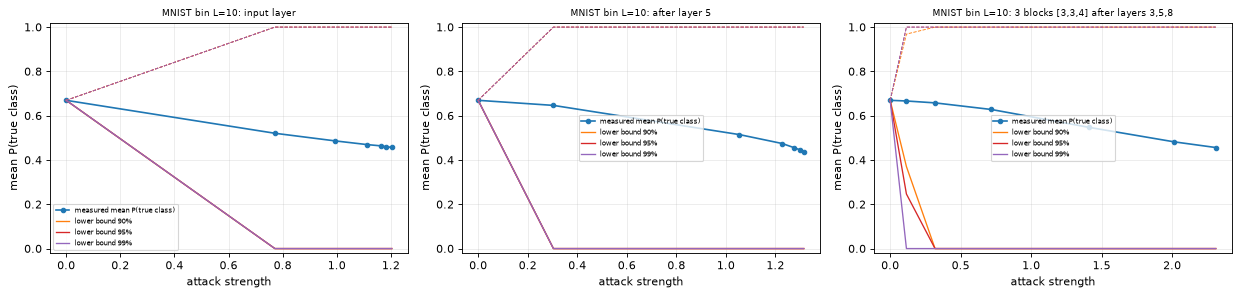

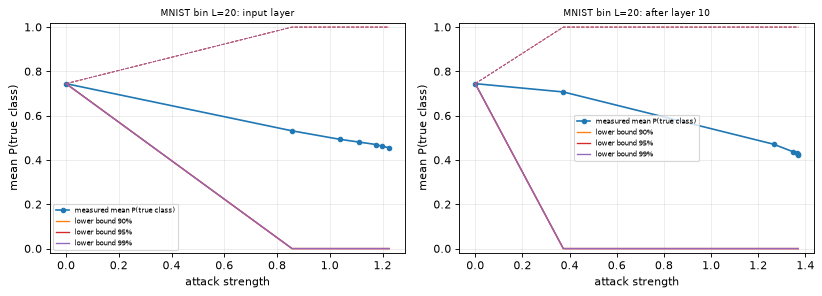

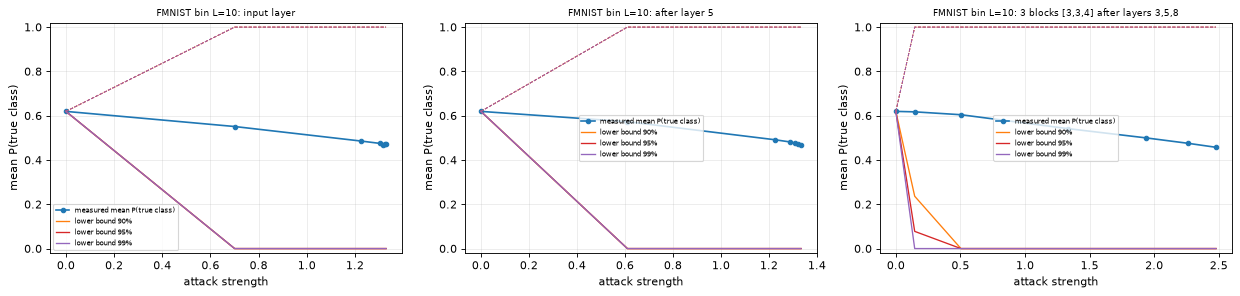

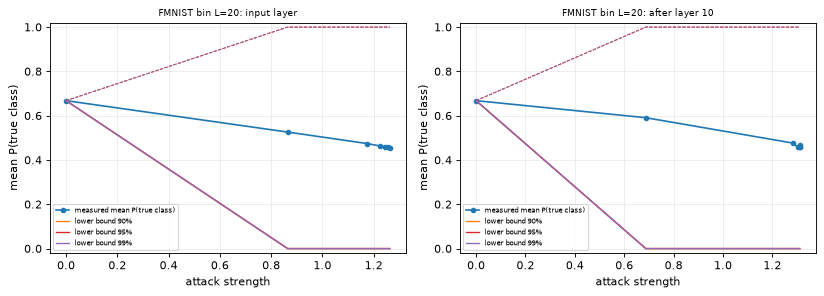

In [25]:
def bound_figure(ds, task, L, scens):
    fig, axes = plt.subplots(1, len(scens), figsize=(5.2 * len(scens), 3.8), squeeze=False)
    ybar = CLF[(ds, task, L)]["Pte"].gather(1, DATA[(ds, task)]["Yte"][:, None]).mean().item()
    for ax, scen in zip(axes[0], scens):
        key = next((k for k in RES if k[:4] == (ds, task, L, scen) and k[4] == SEED), None)
        if key is None: ax.set_visible(False); continue
        h = RES[key]["hist"]; x = np.array([r["strength"] for r in h]); pt = np.array([r["ptrue"] for r in h])
        o = np.argsort(x); ax.plot(x[o], pt[o], "o-", color="tab:blue", ms=4, label="measured mean P(true class)")
        for c, col in zip(CONFS, ("tab:orange", "tab:red", "tab:purple")):
            dl = np.array([r[f"delta{int(round(c * 100))}"] for r in h])
            ax.plot(x[o], np.clip(ybar - dl, 0, 1)[o], color=col, lw=1.2, label=f"lower bound {int(c * 100)}%")
            ax.plot(x[o], np.clip(ybar + dl, 0, 1)[o], color=col, lw=0.8, ls="--")
        ax.set_ylim(-0.02, 1.02); ax.set_xlabel("attack strength"); ax.set_ylabel("mean P(true class)")
        ax.set_title(f"{ds} {task} L={L}: {scen_label(scen, L)}", fontsize=8); ax.legend(fontsize=6)
    plt.tight_layout(); plt.show()

for (ds, task, L) in CLASSIFIERS:
    if task == "bin" and L in (10, 20) and ds in ("MNIST", "FMNIST"):
        bound_figure(ds, task, L, [s for s in ("g:input", "g:q2", "g:3x(3,3,4)", "g:3x10") if any(k[:4] == (ds, task, L, s) for k in RES)][:3])

## 8. Wire cutting versus planting a gate: the paper's Section 4, reproduced exactly on a small instance

The paper does not simulate wire cutting (Appendix C.1: too costly for 9-11 qubit strongly entangled circuits) and argues that *"adversarial perturbations of the prepared states are the same as inserting a gate"*. Here we check this statement numerically on a **5-qubit instance of the same architecture** (4 data qubits = a real MNIST image average-pooled to 4x4, one ancilla, 4 layers). The cut goes across **all five wires** after layer 2, so the circuit really falls into two independent fragments that only communicate through classical numbers:

$$\mathrm{id}^{\otimes 5}(\rho)=\frac1{2^5}\sum_{P\in\{I,X,Y,Z\}^{\otimes5}}\mathrm{Tr}[P\rho]\,P \quad(\text{Eq. 9}),\qquad y_k=\frac1{2^5}\sum_P \underbrace{\mathrm{Tr}[P\rho_A]}_{\text{fragment A measures }P}\;\underbrace{\mathrm{Tr}[\Pi_k\,V_B\,\tilde P\,V_B^\dagger]}_{\text{fragment B is fed }\tilde P}$$

where $\tilde P=P$ for an honest cut and $\tilde P=\tilde U P\tilde U^\dagger$ when the adversary perturbs every prepared state with the same unitary $\tilde U$ (Eq. 13-14). Each $P$ is a difference of eigenstates, so feeding $P$ means preparing its $\pm1$ eigenstates, and the perturbation is applied to those states. The same adversarial layers as in the experiments (rotations + CRZ ring) build $\tilde U$.

In [26]:
import itertools, functools
n5, d5, K5, L5, m5 = 5, 4, 2, 4, 2
lay5 = get_layout(n5)
g5 = torch.Generator().manual_seed(SEED)
w5 = torch.randn(L5, n5, 3, generator=g5)
x_real = DATA[("MNIST", "bin")]["Xte"][0].reshape(16, 16)                           # a real test image
x_pool = x_real.reshape(4, 4, 4, 4).mean(axis=(1, 3)).reshape(-1)                  # 4x4 average pooling -> 16 amplitudes = 4 data qubits
psi0 = encode(torch.tensor(x_pool)[None], n5, d5)[0].to(torch.complex128)
eye = torch.eye(2 ** n5, dtype=CDT)
U_A = classifier_layers(eye, w5[:m5], lay5).T.to(torch.complex128)                   # fragment A: layers 1..m
U_B = classifier_layers(eye, w5[m5:], lay5).T.to(torch.complex128)                   # fragment B: layers m+1..L
Pi = [torch.diag(((torch.arange(2 ** n5) % K5) == k).to(torch.complex128)) for k in range(K5)]    # ancilla = bottom qubit

y_ref = class_probs(run(encode(torch.tensor(x_pool)[None], n5, d5), w5, lay5), n5, d5, K5)[0].double()     # uncut simulator

paulis1 = [torch.eye(2, dtype=torch.complex128), torch.tensor([[0, 1], [1, 0]], dtype=torch.complex128),
           torch.tensor([[0, -1j], [1j, 0]], dtype=torch.complex128), torch.tensor([[1, 0], [0, -1]], dtype=torch.complex128)]
Pstr = torch.stack([functools.reduce(torch.kron, [paulis1[i] for i in idx]) for idx in itertools.product(range(4), repeat=n5)])   # (1024, 32, 32)
rho_A = U_A @ torch.outer(psi0, psi0.conj()) @ U_A.conj().T                                                                     # state leaving fragment A
e_P = torch.einsum("pij,ji->p", Pstr, rho_A).real                                                                               # fragment A "measures" every Pauli string
M = torch.stack([U_B.conj().T @ Pi[k] @ U_B for k in range(K5)])                                                                # fragment B observable for outcome k

def cut_probs(Ptilde):
    # Ptilde: (1024, 32, 32) operators fed to fragment B (the honest cut feeds the Pauli strings themselves)
    T = torch.einsum("kij,pji->pk", M, Ptilde).real
    return (e_P[:, None] * T).sum(0) / 2 ** n5

y_cut = cut_probs(Pstr)
print("uncut simulator           :", y_ref.numpy().round(6))
print("reconstructed from 1024 terms:", y_cut.numpy().round(6), " max diff", float((y_cut - y_ref).abs().max()))
assert float((y_cut - y_ref).abs().max()) < 1e-5

# the adversary: one planted unitary U~ (3 adversarial layers on all 5 qubits, random parameters) applied to every prepared state
a5 = 0.5 * torch.randn(3, n5, 4, generator=g5)
Ut = block_unitary(a5).to(torch.complex128)
Pt = torch.einsum("ij,pjk,kl->pil", Ut, Pstr, Ut.conj().T)
y_cut_adv = cut_probs(Pt)
y_ins = class_probs(run(encode(torch.tensor(x_pool)[None], n5, d5), w5, lay5, [(m5, a5, lay5)]), n5, d5, K5)[0].double()          # gate inserted after layer m
print("\nperturbed prepared states   :", y_cut_adv.numpy().round(6))
print("gate U~ inserted after layer", m5, ":", y_ins.numpy().round(6), " max diff", float((y_cut_adv - y_ins).abs().max()))
assert float((y_cut_adv - y_ins).abs().max()) < 1e-5
print("normalised distance of U~ from the identity:", round(unit_strength(a5), 3), "| confidence shift on this image:", float((y_ins - y_ref).abs().max()))
t61 = thm61([a5], n5, y_ref[None], y_ins[None])
print("Theorem 6.1 on this instance: shift", round(t61["max_dy"], 4), "<= operator-norm bound", round(t61["bound_op"], 4), "<= HS bound", round(t61["bound_hs"], 4))
assert t61["max_dy"] <= t61["bound_op"] + 1e-6

# Eq. 14 with DIFFERENT perturbations per Pauli string: the map is trace preserving but need not be completely positive
a5b = 0.5 * torch.randn(3, n5, 4, generator=g5); Ut2 = block_unitary(a5b).to(torch.complex128)
idx_odd = (torch.arange(len(Pstr)) % 2 == 1)
Pmix = Pt.clone(); Pmix[idx_odd] = torch.einsum("ij,pjk,kl->pil", Ut2, Pstr[idx_odd], Ut2.conj().T)
y_mix = cut_probs(Pmix)
print("\ntwo different perturbations (non-uniform):", y_mix.numpy().round(6), "sum =", float(y_mix.sum()), "(trace preserved, but is it a valid circuit?)")

uncut simulator           : [0.394477 0.605523]
reconstructed from 1024 terms: [0.394477 0.605523]  max diff 1.0294392471799085e-07



perturbed prepared states   : [0.417446 0.582554]
gate U~ inserted after layer 2 : [0.417446 0.582554]  max diff 9.649835336356105e-08
normalised distance of U~ from the identity: 1.293 | confidence shift on this image: 0.02296900749206543
Theorem 6.1 on this instance: shift 0.023 <= operator-norm bound 1.9715 <= HS bound 7.3133

two different perturbations (non-uniform): [0.497562 0.502438] sum = 1.0000000197061176 (trace preserved, but is it a valid circuit?)


In [27]:
# Footnote 2 of the paper: C_adv(rho) = 1/2 ( sum_{P in {I,Y,Z}} Tr(P rho) P + Tr(X rho) U~ X U~^dagger ) with U~ = Z is not completely positive.
I2, X, Y, Z = [p.numpy() for p in paulis1]
def C_adv(rho):
    return 0.5 * (sum(np.trace(P @ rho) * P for P in (I2, Y, Z)) + np.trace(X @ rho) * (Z @ X @ Z.conj().T))
J = np.zeros((4, 4), dtype=complex)                                                  # Choi matrix  J = sum_ij |i><j| (x) C(|i><j|)
for i in range(2):
    for j in range(2):
        E = np.zeros((2, 2), dtype=complex); E[i, j] = 1
        J += np.kron(E, C_adv(E))
CHOI_MIN = float(np.linalg.eigvalsh((J + J.conj().T) / 2).min())
print("Choi eigenvalues of the footnote-2 map:", np.linalg.eigvalsh((J + J.conj().T) / 2).round(4))
print("-> a negative eigenvalue means the map is not completely positive: perturbing the prepared states differently per term can break the circuit,")
print("   which is why the paper's adversary uses ONE unitary for all prepared states (which is an inserted gate, Eq. 13).")

Choi eigenvalues of the footnote-2 map: [-1.  1.  1.  1.]
-> a negative eigenvalue means the map is not completely positive: perturbing the prepared states differently per term can break the circuit,
   which is why the paper's adversary uses ONE unitary for all prepared states (which is an inserted gate, Eq. 13).


## 9. Side by side with the paper: one verdict per claim

The paper reports **numbers only for the clean accuracies (Table 1)**; everything adversarial is shown in Figures 8-33 and described in words. The qualitative claims are therefore tested with the comparisons of section 6.2 (a claim is "reproduced" when the stated tendency appears in the stated share of cases, "not reached" when it does not, "cannot be checked" when the configuration that would test it was not run). Numbers are accuracies in %, percentage points otherwise; the tolerance for Table 1 is 2 points.

In [28]:
V = []
for _, r in TABLE1.iterrows():
    if pd.notna(r["paper acc %"]):
        V.append(dict(claim=f"Table 1: clean test accuracy, {r['dataset']} {r['task']} {r['layers']} layers", paper=f"{r['paper acc %']:.2f}%",
                      notebook=f"{r['quantum acc %']:.2f}% (SVC-rbf {r['SVC-rbf acc %']:.1f}%, RF {r['RF acc %']:.1f}%)", verdict=r["verdict"]))
for (ds, task, L), p in PAPER_T1.items():
    if (ds, task, L) not in CLF:
        V.append(dict(claim=f"Table 1: clean test accuracy, {ds} {task} {L} layers", paper=f"{p:.2f}%", notebook="not trained (budget)", verdict="cannot be checked"))

def share(claim, thr=2.0):
    sub = CMP[CMP["claim"].str.startswith(claim)]
    if len(sub) == 0: return 0, 0, 0, None
    return len(sub), int((sub["A_minus_B_points"] >= thr).sum()), int((sub["A_minus_B_points"] <= -thr).sum()), float(sub["A_minus_B_points"].max())

n, pos, neg, best = share("mid-circuit")
V.append(dict(claim="A block planted in an intermediate layer can be MORE successful than one at the input (App. C.3.2.1, 'in some instances')",
              paper="qualitative (Figs. 8a, 10b, 11b, 12, 13a, 16-19)",
              notebook="no comparison run" if n == 0 else f"{pos} of {n} mid-vs-input comparisons favour the mid-circuit block by >= 2 points (best {best:+.1f}); input block better in {neg}",
              verdict="cannot be checked" if n == 0 else ("reproduced" if pos >= 1 else "not reached")))
n, pos, neg, best = share("global vs local")
V.append(dict(claim="Global adversarial gates often beat local ones, but not always (App. C.3.2.2)", paper="qualitative (Figs. 13-20 vs 8-11)",
              notebook="no comparison run" if n == 0 else f"global better by >= 2 points in {pos} of {n} comparisons, local better in {neg}",
              verdict="cannot be checked" if n == 0 else ("reproduced" if pos >= n / 2 else "not reached")))
n, pos, neg, best = share("single block vs three")
V.append(dict(claim="At equal summed attack strength a single block often beats three blocks (App. C.3.2.1)", paper="qualitative (Figs. 8-12)",
              notebook="no comparison run" if n == 0 else f"single block better by >= 2 points in {pos} of {n} comparisons, three blocks better in {neg}",
              verdict="cannot be checked" if n == 0 else ("reproduced" if pos >= n / 2 else "not reached")))
n, pos, neg, best = share("more adversarial layers")
V.append(dict(claim="Blocks with more layers are more successful (App. C.3.2.3)", paper="qualitative (Figs. 12, 21, 22: 40 vs 10 layers)",
              notebook="no comparison run" if n == 0 else f"the larger block is better by >= 2 points in {pos} of {n} comparisons (worse in {neg})",
              verdict="cannot be checked" if n == 0 else ("reproduced" if pos >= n / 2 else "not reached")))

dep = []
for ds in ("MNIST", "FMNIST"):
    if (ds, "bin", 10) in CLF and (ds, "bin", 20) in CLF and have(ds, "bin", 10, "g:q2") and have(ds, "bin", 20, "g:q2"):
        s_max = min(curve(ds, "bin", 10, "g:q2")[0].max(), curve(ds, "bin", 20, "g:q2")[0].max())
        dep.append((ds, mean_mis(ds, "bin", 20, "g:q2", s_max) - mean_mis(ds, "bin", 10, "g:q2", s_max)))
V.append(dict(claim="A deeper classifier is not necessarily more robust (App. C.3.2.3, Figs. 10-11)", paper="qualitative (four-class 20 vs 40 layers)",
              notebook="binary 10 vs 20 layers not both run" if not dep else "; ".join(f"{d}: 20-layer minus 10-layer mean misclassification {v:+.1f} points" for d, v in dep),
              verdict="cannot be checked" if not dep else ("reproduced" if any(v > -2 for _, v in dep) else "not reached")))

V.append(dict(claim="Theorem 6.1: |y_k - y^_k| <= sum_i min_phi ||I - e^{i phi} U_i||_op <= (HS version)", paper="proved (Sec. 6, App. A)",
              notebook=f"holds in {int(THM61['holds'].sum())} of {len(THM61)} attacks; largest ratio shift/bound = {float((THM61['max_shift'] / THM61['bound_operator_norm'].clip(lower=1e-9)).max()):.2f}",
              verdict="reproduced" if bool(THM61["holds"].all()) and len(THM61) else "cannot be checked"))

inf = THM63.dropna(subset=["coverage_in_informative_epochs"])
if len(inf):
    worst = float((inf["coverage_in_informative_epochs"] - inf["confidence"]).min())
    ok63 = worst >= -0.02
    ev63 = (f"{len(inf)} (run, confidence) pairs with an informative bound (delta < 0.5); coverage minus nominal confidence: worst {worst:+.3f}, "
            f"mean {float((inf['coverage_in_informative_epochs'] - inf['confidence']).mean()):+.3f}")
else:
    ok63, ev63 = False, "no epoch with an informative bound (delta < 0.5)"
V.append(dict(claim="Theorem 6.3: |y_k - y^_k| < delta holds for at least a fraction c of inputs (Haar-random in the theorem; real images here)", paper="proved; empirically 'useful' (Figs. 29-33)",
              notebook=ev63, verdict="reproduced" if (len(inf) and ok63) else ("cannot be checked" if not len(inf) else "not reached")))

gaps, within = [], []
for job, R in RES.items():
    ds, task, L, scen, sd = job
    if task != "bin": continue
    ybar = CLF[(ds, task, L)]["Pte"].gather(1, DATA[(ds, task)]["Yte"][:, None]).mean().item()
    for r in R["hist"][1:]:
        if r["delta90"] < 0.5:
            lb = ybar - r["delta90"]; within.append(r["ptrue"] >= lb); gaps.append(r["ptrue"] - lb)
V.append(dict(claim="The 90%/95% lower bounds of Theorem 6.3 are close to the measured true-class probability at small attack strength (App. C.4)", paper="qualitative (Figs. 29-33)",
              notebook="no informative epoch" if not gaps else f"{len(gaps)} informative epochs (binary): measured P(true) above the 90% lower bound in {100 * np.mean(within):.0f}% of them, mean gap {np.mean(gaps):.3f}",
              verdict="cannot be checked" if not gaps else ("reproduced" if (np.mean(within) >= 0.9 and np.mean(gaps) <= 0.15) else "not reached")))

V.append(dict(claim="Sec. 4: perturbing every prepared state of a wire cut with one unitary equals inserting that gate (Eq. 13)", paper="proved",
              notebook=f"5-qubit instance, 1024-term cut: max |difference| = {float((y_cut_adv - y_ins).abs().max()):.1e} (honest cut: {float((y_cut - y_ref).abs().max()):.1e})",
              verdict="reproduced" if float((y_cut_adv - y_ins).abs().max()) < 1e-5 else "not reached"))
V.append(dict(claim="Footnote 2: per-term different perturbations can give a map that is not completely positive", paper="shown analytically",
              notebook=f"smallest Choi eigenvalue of the footnote map = {CHOI_MIN:.3f}", verdict="reproduced" if CHOI_MIN < -1e-9 else "not reached"))
V.append(dict(claim="Figs. 21-28 (CIFAR-2 local gates, gamma sweeps), four-class depth 40, 3 seeds for every curve, full datasets", paper="plots",
              notebook="not run (CPU budget)", verdict="cannot be checked"))

VERD = pd.DataFrame(V)
pd.set_option("display.max_colwidth", 200, "display.width", 250)
display(VERD)
print(VERD["verdict"].value_counts().to_string())
mx = max((R["hist"][-1]["strength"] / len(R["bspec"])) for R in RES.values())
print(f"\nlargest normalised distance of a single block reached by any attack: {mx:.2f} (the paper's caption says the maximum for two unitaries is sqrt(2) = {math.sqrt(2):.2f})")
print(f"total notebook run time: {(time.time() - T_NOTEBOOK_START) / 60:.1f} min  (FAST_MODE={FAST_MODE})")

,claim,paper,notebook,verdict
0,"Table 1: clean test accuracy, MNIST bin 10 layers",99.67%,"99.80% (SVC-rbf 99.8%, RF 99.9%)",reproduced
1,"Table 1: clean test accuracy, MNIST bin 20 layers",99.86%,"99.60% (SVC-rbf 99.8%, RF 99.9%)",reproduced
2,"Table 1: clean test accuracy, FMNIST bin 10 layers",94.80%,"94.60% (SVC-rbf 97.7%, RF 97.4%)",reproduced
3,"Table 1: clean test accuracy, FMNIST bin 20 layers",94.75%,"94.80% (SVC-rbf 97.7%, RF 97.4%)",reproduced
4,"Table 1: clean test accuracy, MNIST 4c 20 layers",90.40%,"90.62% (SVC-rbf 99.0%, RF 98.1%)",reproduced
5,"Table 1: clean test accuracy, FMNIST 4c 20 layers",79.80%,"88.00% (SVC-rbf 91.0%, RF 92.1%)",exceeded
6,"Table 1: clean test accuracy, CIFAR10 cifar2 80 layers",83.05%,"80.00% (SVC-rbf 86.5%, RF 84.5%)",not reached
7,"Table 1: clean test accuracy, MNIST 4c 40 layers",92.18%,not trained (budget),cannot be checked
8,"Table 1: clean test accuracy, FMNIST 4c 40 layers",84.18%,not trained (budget),cannot be checked
9,"A block planted in an intermediate layer can be MORE successful than one at the input (App. C.3.2.1, 'in some instances')","qualitative (Figs. 8a, 10b, 11b, 12, 13a, 16-19)",1 of 11 mid-vs-input comparisons favour the mid-circuit block by >= 2 points (best +7.5); input block better in 7,reproduced


verdict
reproduced           14
cannot be checked     3
not reached           2
exceeded              1

largest normalised distance of a single block reached by any attack: 1.41 (the paper's caption says the maximum for two unitaries is sqrt(2) = 1.41)
total notebook run time: 90.5 min  (FAST_MODE=False)


## 10. Reading the paper critically

* **The headline "partitioning makes quantum classifiers more vulnerable" is an observation about attack surface, not a measurement of two comparable attackers.** A mid-circuit block and an input block are compared at equal *summed normalised Hilbert-Schmidt distance* and equal number of layers, but the three-block adversary has three times as many parameters, a unitary's distance from the identity says nothing about how far it moves the *states of the data set*, and the distance is not invariant under a global phase (which does nothing physically; Theorem 6.1 takes the minimum over it). Part of the section 6.2 comparisons therefore measures the choice of metric.
* **In our runs the input-layer attack is usually the stronger one.** Section 9 shows that the mid-circuit block beat the input block by at least 2 points in only 1 of 11 comparisons (and was worse in 7), so the paper's 'in some instances' is, at this budget, a rare event; the extra surface matters because the attacker gains additional places to attack, not because each place is easier. Likewise the 'single block beats three blocks' result is partly a consequence of summing distances: three blocks reach large summed strengths with each block barely moved.
* **The classifiers are not strong.** Four-class Fashion-MNIST at 79.8% and a CIFAR-2 model at 83% are far from the classical state of the art on the same tasks, and the same inputs fed to an RBF-SVM or a random forest (table in section 4) do better in every case we ran. How "robust" a weak classifier is, is hard to interpret.
* **The attacker is very strong.** White-box access to the frozen weights, an unconstrained ($\gamma=0$) gate that is trained on the training set for as long as it helps. For the wire-cutting story the realistic question is whether a malicious *node* knows the weights of the other fragments; the notebook (like the paper) does not model a black-box adversary.
* **Equal perturbation of all prepared states.** Section 4 shows that only a *common* unitary applied to all prepared states yields a valid circuit; the footnote-2 example above shows what goes wrong otherwise. A less careful adversary produces a non-physical reconstruction, which a verifier may detect (negative or super-normalised probabilities in the post-processing); the paper does not discuss detection.
* **Theorem 6.3 needs Haar-random inputs, no ancillas and a unital channel**; the experiments use amplitude-encoded images (non-negative, highly structured), an ancilla in $|0\rangle$ and Haar-agnostic constants that we had to choose (table at the top). The theorem is only informative for tiny perturbations (the half-width $\delta_c$ grows with the square root of $\sum_i\|I-\hat U_i\|_2^2/(1-c)$); this is consistent with the paper's own conclusion that it helps for "stealthy" attacks, but the bound is of little use once an attack succeeds.
* **The distance scale.** The paper states that the maximum normalised Hilbert-Schmidt distance between two unitaries is $\sqrt2$. For $\|U-I\|_2/\sqrt D$ the true maximum is 2 (for $U=-I$); $\sqrt2$ is the value of a *typical* (Haar-random) unitary, since $\mathbb E\|U-I\|_2^2/D=2$. In our runs every single block saturates at about 1.41, i.e. the unconstrained attacks end at a random-looking unitary, so a three-block attack would end near $3\sqrt2\approx4.2$ if all blocks saturated (the paper's $3\sqrt2$ in Figure 8's caption is a typical value, not a maximum); ours end at 2.3-2.9 because the blocks are far from saturated.
* **Figures without numbers.** Apart from Table 1 the paper provides no tabulated adversarial result, so a "reproduction" can only confirm tendencies (done above), not values.
* **This notebook's own limits.** Smaller training sets and far fewer epochs than the paper, one classifier seed per configuration, the attack learning rate and the number of attack epochs chosen by us, four-class depth 40 and the CIFAR-2 local-gate figures not run. Take the verdicts as statements about *this* budget.

## 11. Exercises

1. **Strength penalty.** Implement the $\ell_2$ term of Eq. 35 (maximise `loss + gamma * ||a||_2` with $\gamma>0$) and re-run one scenario with $\gamma\in\{0.5,1,1.5\}$. Do the constrained curves follow the early epochs of the unconstrained one (Figs. 25-28)?
2. **Depth 40.** Add `("MNIST", "4c", 40)` and `("FMNIST", "4c", 40)` to `CLASSIFIERS` and compare the robustness of the 20- and 40-layer four-class models (paper Figs. 10-11). Is the deeper model more robust in your budget?
3. **Cut only some wires.** In section 8 cut only two of the five wires (a 16-term decomposition on those wires, nothing on the others) and insert a 2-qubit adversarial unitary on them. Verify the equivalence with a 2-qubit gate inserted at the same place.
4. **Phase-invariant strength.** Replace the strength by $\min_\phi\|e^{i\phi}U-I\|_2/\sqrt{D}$ and re-plot Figure 8-style curves. Does the ranking input / mid-circuit / three blocks change?
5. **Query-limited adversary.** Replace back-propagation in `run_attack` by the parameter-shift rule (two circuit evaluations per parameter). How many circuit executions does an attack that reaches 50% misclassification need for a global 10-layer block on 9 qubits, and what does that mean for a malicious node that only has black-box access?